# Vulnerable Growth

Tobias Adrian, Nina Boyarchenko and Domenico Giannone, *American Economic Review* 109(4), 2019, pp. 1263–1289.

Replication by **Lorenzo Giordani**.

Equation and figure numbers refer to the working-paper version, [Federal Reserve Bank of New York Staff Report 794](https://www.newyorkfed.org/research/staff_reports/sr794.html) (revised November 2017), which has the same figures as the published article.

**The question.** Do financial conditions help predict the whole distribution of future GDP growth, and not only its mean? The paper's answer is that current economic conditions predict the median, while financial conditions predict the downside: when the National Financial Conditions Index (NFCI) tightens, the left tail of future growth moves down much more than the centre, and the right tail barely moves. The resulting measure of downside risk is now known as *Growth-at-Risk*.

**Method, in two steps.**
1. Quantile regressions of future GDP growth on current GDP growth and the NFCI give, every quarter, a set of predicted conditional quantiles.
2. A skewed $t$-distribution is fitted to four of those quantiles each quarter, which turns them into a full predictive density.

**Data.** Everything comes from one file, `data/DataVulnerability.xlsx` (sheet `Data`): real GDP growth (FRED `A191RL1Q225SBEA`, annualised quarter-on-quarter, %) and the Chicago Fed NFCI, quarterly, 1973Q1–2015Q4.

**Contents.**
1. Data (Figure 2)
2. Quantile regression
3. Figure 3: univariate and multivariate quantile regressions
4. Figure 4: coefficients across quantiles, with VAR bootstrap bands
5. Figures 5 and 6: predicted quantiles over time
6. The skewed $t$-distribution
7. Fitting the skewed $t$ every quarter
8. Figure 1 (3D) and Figures 7–8: densities and quantile functions
9. Measuring vulnerability: entropy and expected shortfall (Figure 9)
10. Parameters and moments over time (Figures A.1–A.4)
11. Out-of-sample analysis (Figures 10 and 11)
12. Location-scale models and alternative approaches (Figures 12 and A.8)
13. Implications for macro theory (Figures 13 and 14)
14. Summary and differences from the paper

In [1]:
import time
import warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import optimize, sparse, stats
from scipy.optimize import linprog
from scipy.stats import gaussian_kde, norm

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- settings ----
DATA_FILE = "data/DataVulnerability.xlsx"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
H = [1, 4]                                        # forecast horizons, quarters
QQ = np.round(np.arange(0.05, 0.951, 0.05), 2)    # the 19 quantiles of the paper
TAU_FIT = np.array([0.05, 0.25, 0.75, 0.95])      # quantiles matched by the skewed t
NBOOT = 1000                                      # VAR bootstrap draws (as in the paper)
SEED = 1234
OOS_START = "1993-01-01"                          # first out-of-sample forecast origin

BLUE, RED, GREY = "#145b8e", "#c0392b", "#8c8c8c"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 9, "axes.titlesize": 9.5, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "legend.frameon": False, "legend.fontsize": 8,
})

# NBER recessions, peak to trough (quarters)
NBER = [("1973Q4", "1975Q1"), ("1980Q1", "1980Q3"), ("1981Q3", "1982Q4"),
        ("1990Q3", "1991Q1"), ("2001Q1", "2001Q4"), ("2007Q4", "2009Q2")]

def shade(ax):
    for a, b in NBER:
        ax.axvspan(pd.Period(a).start_time, pd.Period(b).end_time, color="0.88", lw=0, zorder=0)

def time_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def jq(tau):
    """position of quantile tau in QQ"""
    return int(np.argmin(np.abs(QQ - tau)))

def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

def legend_below(fig, axes, ncol=None):
    """one legend for the whole figure, below the panels (collects unique labels from axes)"""
    handles, labels = [], []
    for ax in np.atleast_1d(axes).ravel():
        for hd, lb in zip(*ax.get_legend_handles_labels()):
            if lb not in labels and not lb.startswith("_"):
                handles.append(hd); labels.append(lb)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol or len(labels))

## 1. Data

The sample is 1973Q1–2015Q4, 172 quarters, as in the paper. GDP growth is the annualised quarter-on-quarter growth rate of real GDP, in percent. The NFCI is a weighted average of 105 indicators of risk, credit and leverage. It is normalised to mean zero and standard deviation one over its history, and **positive values mean tighter-than-average financial conditions**.

**Dependent variable.** For horizon $h$ the regressions use the average annualised growth over the next $h$ quarters,

$$y_{t+h} = \frac{1}{h}\sum_{j=1}^{h}\mathrm{GDP}_{t+j},$$

so $y_{t+1}$ is next quarter's growth and $y_{t+4}$ is growth over the next year. With $T = 172$ quarters this leaves $T-1 = 171$ observations for $h = 1$ and $T-4 = 168$ for $h = 4$. Every quarter of these samples later gets its own predictive distribution.

In [2]:
raw = pd.read_excel(DATA_FILE, sheet_name="Data")
raw.columns = ["date", "gdp", "nfci"]
raw = raw[(raw["date"] >= "1973-01-01") & (raw["date"] <= "2015-10-01")].reset_index(drop=True)

dates = pd.DatetimeIndex(raw["date"])
gdp, nfci = raw["gdp"].to_numpy(), raw["nfci"].to_numpy()
T = len(gdp)

def target(h, g=gdp):
    """y[t] = average growth over t+1..t+h, for t = 0..len(g)-h-1"""
    return np.array([g[t + 1:t + h + 1].mean() for t in range(len(g) - h)])

Y  = {h: target(h) for h in H}                                                # dependent variable
X  = {h: np.column_stack([np.ones(T - h), gdp[:T - h], nfci[:T - h]]) for h in H}  # [1, GDP_t, NFCI_t]
XG = {h: X[h][:, :2] for h in H}                                              # GDP only
CDATE = {h: dates[:T - h] for h in H}    # conditioning date t
TDATE = {h: dates[h:] for h in H}        # target date t+h (used on time axes, as in the paper)

print(f"{T} quarters, {dates[0]:%Y}Q1–{dates[-1]:%Y}Q{dates[-1].quarter}; "
      f"observations: h=1 -> {len(Y[1])}, h=4 -> {len(Y[4])}")
raw[["gdp", "nfci"]].describe().T.round(2)[["mean", "std", "min", "max"]]

172 quarters, 1973Q1–2015Q4; observations: h=1 -> 171, h=4 -> 168


,mean,std,min,max
gdp,2.75,3.28,-8.2,16.50
nfci,0.01,0.99,-1.0,4.24


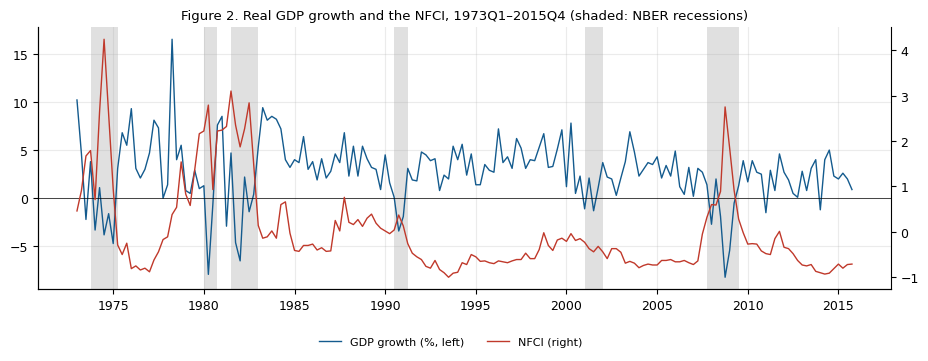

In [3]:
# Figure 2: GDP growth and the NFCI
fig, ax = plt.subplots(figsize=(11, 3.4))
shade(ax)
ax.plot(dates, gdp, color=BLUE, lw=1, label="GDP growth (%, left)")
ax.axhline(0, color="k", lw=0.5)
ax2 = ax.twinx()
ax2.plot(dates, nfci, color=RED, lw=1, label="NFCI (right)")
ax2.grid(False); ax2.spines["right"].set_visible(True)
time_axis(ax)
fig.legend(handles=ax.get_lines()[:1] + ax2.get_lines(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
ax.set_title("Figure 2. Real GDP growth and the NFCI, 1973Q1–2015Q4 (shaded: NBER recessions)")
save(fig, "fig02_gdp_nfci.png"); plt.show()

The large falls in GDP growth coincide with spikes in the NFCI: 1974–75 (the NFCI peaks at 4.24 in 1974Q3), 1980–82 and 2008, when growth hits its sample minimum of $-8.2\%$ in 2008Q4. Outside these episodes the NFCI is mostly below zero (it rises only mildly, to at most 0.76, in 1987–91) and growth fluctuates around 3%. Over the whole sample the two series are negatively correlated ($-0.36$): tight financial conditions tend to come with weak current growth, which matters for Figure 3.

## 2. Quantile regression

### From the conditional mean to conditional quantiles

OLS estimates the conditional **mean** of $y_{t+h}$ given $x_t = (1,\ \mathrm{GDP}_t,\ \mathrm{NFCI}_t)$ by minimising squared residuals:

$$\hat\beta_{OLS} = \arg\min_\beta \sum_t \left(y_{t+h} - x_t\beta\right)^2 .$$

One coefficient vector, one forecast: the predictors can shift the centre of the distribution but say nothing about its shape. Quantile regression (Koenker and Bassett, 1978) instead estimates the conditional **$\tau$-quantile** for each $\tau\in(0,1)$, with no assumption on the distribution of the errors:

$$\hat\beta_\tau = \arg\min_{\beta}\sum_{t}\rho_\tau\!\left(y_{t+h}-x_t\beta\right),
\qquad
\rho_\tau(u)=\begin{cases}\tau\,|u| & u\ge 0 \ \ \text{(forecast too low)}\\ (1-\tau)\,|u| & u<0 \ \ \text{(forecast too high)}\end{cases}$$

### Why asymmetric weights produce quantiles

| $\tau$ | weight on under-prediction | weight on over-prediction | result |
|---|---|---|---|
| 0.50 | 0.50 | 0.50 | median: both errors cost the same |
| 0.05 | 0.05 | 0.95 | over-predicting costs 19 times more, so the line moves down until only 5% of observations lie below it |
| 0.95 | 0.95 | 0.05 | the mirror image: only 5% lie above |

The fitted value is the **predicted conditional quantile**,

$$\hat Q_{y_{t+h}\mid x_t}(\tau\mid x_t) = x_t\hat\beta_\tau ,$$

which answers: *given today's conditions, below which growth rate will $100\tau\%$ of outcomes fall?* Each $\tau$ has its own coefficient vector, estimated separately; the paper uses the 19 quantiles $\tau = 0.05, 0.10, \dots, 0.95$.

### Two differences from OLS

1. **Absolute instead of squared residuals:** large errors are not squared, so the estimates are robust to outliers.
2. **Asymmetric instead of symmetric weights:** $\tau$ and $1-\tau$ let each quantile respond differently to the predictors. If the NFCI coefficient is much more negative at $\tau = 0.05$ than at $\tau = 0.95$, tighter financial conditions stretch the left tail without moving the right one.

### Estimation

The minimisation is a linear programme. We solve it exactly with the HiGHS solver: write each residual as $u_t = u_t^+ - u_t^-$ with $u_t^\pm\ge 0$ and minimise $\sum_t \tau u_t^+ + (1-\tau)u_t^-$ subject to $y = X\beta + u^+ - u^-$. (The default solver in `statsmodels` uses iteratively reweighted least squares, which only approximates the solution; at $\tau = 0.35$ it gives a visibly different line.)

In [4]:
def qreg(y, X, taus):
    """Exact quantile regression by linear programming. Returns coefficients, shape (len(taus), k)."""
    n, k = X.shape
    A = sparse.hstack([sparse.csr_matrix(X), sparse.eye(n), -sparse.eye(n)]).tocsr()
    bounds = [(None, None)] * k + [(0, None)] * (2 * n)
    taus = np.atleast_1d(taus)
    B = np.empty((len(taus), k))
    for i, tau in enumerate(taus):
        c = np.r_[np.zeros(k), np.full(n, tau), np.full(n, 1 - tau)]
        B[i] = linprog(c, A_eq=A, b_eq=y, bounds=bounds, method="highs").x[:k]
    return B

B   = {h: qreg(Y[h], X[h], QQ) for h in H}     # GDP + NFCI, 19 quantiles
BG  = {h: qreg(Y[h], XG[h], QQ) for h in H}    # GDP only
OLS = {h: np.linalg.lstsq(X[h], Y[h], rcond=None)[0] for h in H}
YQ  = {h: X[h] @ B[h].T for h in H}            # predicted quantiles, (n_h, 19)
YQG = {h: XG[h] @ BG[h].T for h in H}

rows = {}
for h in H:
    for name, b in [("Q05", B[h][jq(.05)]), ("Q50", B[h][jq(.5)]), ("Q95", B[h][jq(.95)]), ("OLS", OLS[h])]:
        rows[(f"h={h}", name)] = dict(zip(["constant", "GDP", "NFCI"], b))
pd.DataFrame(rows).T.round(3)

constant    GDP   NFCI
h=1 Q05    -2.845  0.416 -2.521
    Q50     2.274  0.129 -1.055
    Q95     5.685  0.362  0.028
    OLS     2.111  0.224 -1.135
h=4 Q05    -0.985  0.238 -1.981
    Q50     2.509  0.078 -0.745
    Q95     5.715  0.178  1.378
    OLS     2.450  0.106 -0.731

The table shows the paper's key asymmetry.
- **NFCI.** The coefficient falls steeply from the top to the bottom of the distribution: at $h=1$ it is $-2.52$ at the 5th percentile, $-1.06$ at the median and essentially zero ($0.03$) at the 95th. A one-standard-deviation tightening lowers the 5th percentile of next quarter's growth by about 2.5 points and leaves the 95th percentile where it is. At $h=4$ the pattern is the same ($-1.98$, $-0.75$), and at the 95th percentile the coefficient even turns positive ($1.38$).
- **Current GDP.** The coefficient is positive at every quantile shown (0.13–0.42 at $h=1$, 0.08–0.24 at $h=4$), somewhat larger in the tails than at the median, with no systematic slope across $\tau$ (Figure 4 shows it is mostly inside the bootstrap bands): current growth shifts the whole distribution rather than reshaping it.
- **OLS** is close to the median regression, as expected, and hides the asymmetry entirely.

## 3. Figure 3: univariate and multivariate quantile regressions

Figure 3 of the paper is a first look at the data: future growth against **one predictor at a time**. Each panel is a *univariate* regression, $Q_\tau(y_{t+h}\mid z_t) = a_\tau + b_\tau z_t$ with $z_t$ either current GDP growth or the NFCI. The main specification of the paper, used from Figure 4 onwards, is *multivariate*: both predictors enter together.

The two versions answer different questions, so we show both:
- **univariate (the paper's Figure 3):** the raw relationship between future growth and each predictor, with nothing held fixed;
- **multivariate:** the line $\hat Q_\tau = \hat\alpha_\tau + \hat\beta^{GDP}_\tau\,\overline{\mathrm{GDP}} + \hat\beta^{NFCI}_\tau z$ for the NFCI panels (and the analogue for GDP), i.e. the effect of one predictor *holding the other at its sample mean*. Its slope is exactly the coefficient in Figure 4.

In [5]:
FIG3_TAUS = [0.05, 0.50, 0.95]
uni = {}    # univariate fits: (h, predictor) -> (quantile coefficients, OLS coefficients)
for h in H:
    for j, name in [(1, "GDP"), (2, "NFCI")]:
        Z = X[h][:, [0, j]]
        uni[(h, name)] = (qreg(Y[h], Z, FIG3_TAUS), np.linalg.lstsq(Z, Y[h], rcond=None)[0])

print("Slopes on the NFCI, univariate vs multivariate")
pd.DataFrame({(f"h={h}", kind): dict(zip(["Q05", "Q50", "Q95", "OLS"],
                list(uni[(h, "NFCI")][0][:, 1]) + [uni[(h, "NFCI")][1][1]]) if kind == "univariate"
                else dict(zip(["Q05", "Q50", "Q95", "OLS"], [B[h][jq(t)][2] for t in FIG3_TAUS] + [OLS[h][2]])))
              for h in H for kind in ["univariate", "multivariate"]}).round(2)

Slopes on the NFCI, univariate vs multivariate


h=1                     h=4             
    univariate multivariate univariate multivariate
Q05      -2.87        -2.52      -2.88        -1.98
Q50      -1.17        -1.05      -0.72        -0.74
Q95       0.29         0.03       0.22         1.38
OLS      -1.41        -1.13      -0.86        -0.73

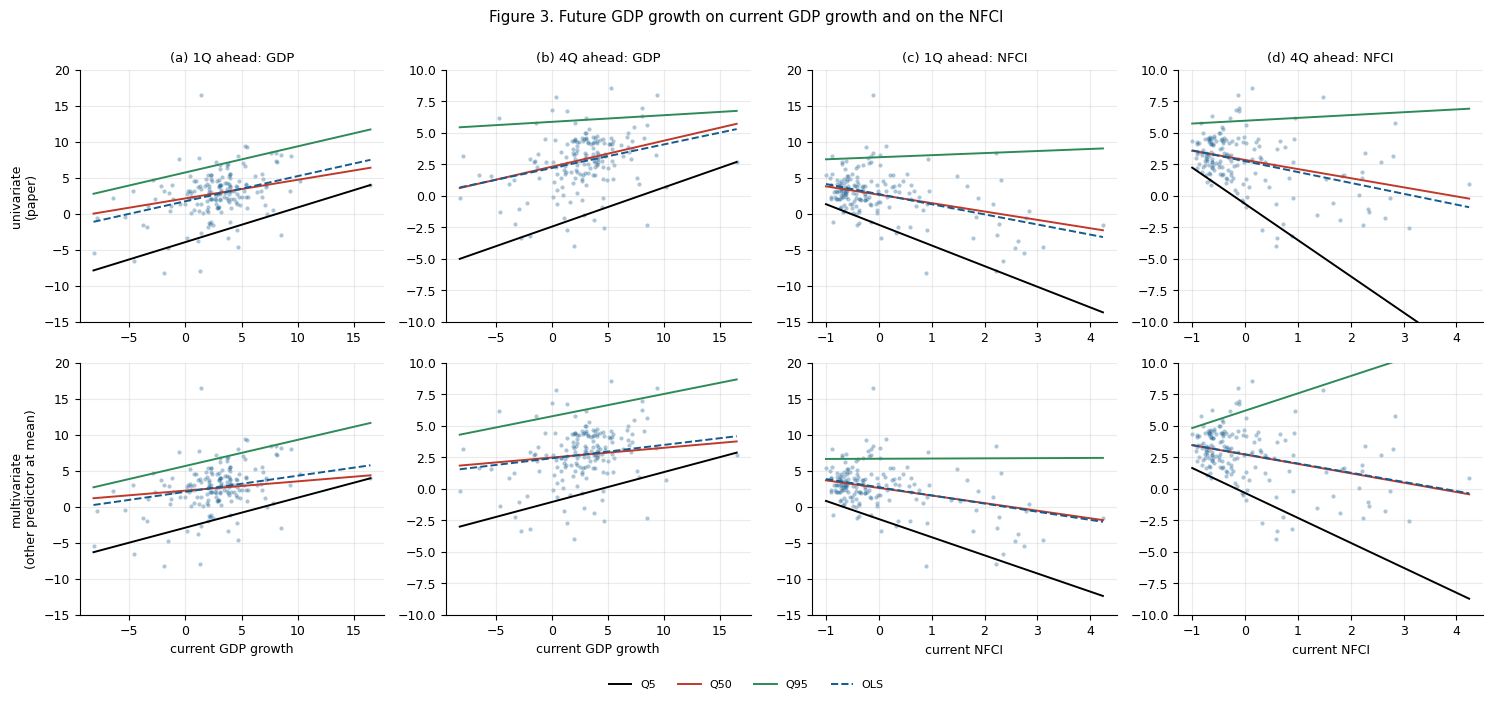

In [6]:
STYLE = {0.05: ("k", "Q5"), 0.50: (RED, "Q50"), 0.95: ("#2e8b57", "Q95")}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6), sharey="col")
panels = [(1, "GDP", "(a) 1Q ahead: GDP"), (4, "GDP", "(b) 4Q ahead: GDP"),
          (1, "NFCI", "(c) 1Q ahead: NFCI"), (4, "NFCI", "(d) 4Q ahead: NFCI")]
for col, (h, name, title) in enumerate(panels):
    j = 1 if name == "GDP" else 2
    z = X[h][:, j]
    grid = np.linspace(z.min(), z.max(), 100)
    other = X[h][:, 3 - j].mean()
    for row in range(2):
        ax = axes[row, col]
        ax.scatter(z, Y[h], s=9, color=BLUE, alpha=0.35, lw=0)
        if row == 0:                                   # univariate, as in the paper
            Bq, bo = uni[(h, name)]
            lines = [(t, Bq[i, 0] + Bq[i, 1] * grid) for i, t in enumerate(FIG3_TAUS)]
            ols_line = bo[0] + bo[1] * grid
        else:                                          # multivariate, other predictor at its mean
            def line(b):
                Zg = np.column_stack([np.ones_like(grid), grid, np.full_like(grid, other)]) if j == 1 \
                     else np.column_stack([np.ones_like(grid), np.full_like(grid, other), grid])
                return Zg @ b
            lines = [(t, line(B[h][jq(t)])) for t in FIG3_TAUS]
            ols_line = line(OLS[h])
        for t, yl in lines:
            ax.plot(grid, yl, color=STYLE[t][0], label=STYLE[t][1])
        ax.plot(grid, ols_line, color=BLUE, ls="--", label="OLS")
        ax.set_ylim(-15, 20) if h == 1 else ax.set_ylim(-10, 10)
        if row == 0: ax.set_title(title)
        if row == 1: ax.set_xlabel("current " + ("GDP growth" if name == "GDP" else "NFCI"))
axes[0, 0].set_ylabel("univariate\n(paper)"); axes[1, 0].set_ylabel("multivariate\n(other predictor at mean)")
fig.suptitle("Figure 3. Future GDP growth on current GDP growth and on the NFCI", y=1.0)
fig.tight_layout(); legend_below(fig, axes[0, 3]); save(fig, "fig03_scatter_qr.png"); plt.show()

**Univariate versus multivariate.** The two rows differ mainly in the upper quantiles of the NFCI panels. In the univariate fits (the paper's figure) the 95th-percentile line is almost flat: slope $0.29$ at $h=1$ and $0.22$ at $h=4$. In the multivariate fit at $h=4$ it becomes steeply positive ($1.38$). The main reason is the negative correlation between the NFCI and current growth ($-0.36$): a univariate NFCI line also absorbs the (positive) effect of current GDP growth, which is low when the NFCI is high, and this pulls its slope down. Holding GDP fixed removes that channel. For quantile regressions this omitted-variable logic holds only approximately: at $h=1$ the 95th-percentile slope is in fact slightly *higher* in the univariate fit ($0.29$ against $0.03$). The lower quantiles are robust: the 5th-percentile slope is about $-2.9$ in the univariate fits and $-2.5$ / $-2.0$ in the multivariate ones. So the flat 95th percentile in the paper's Figure 3 is not a plotting artefact: it is the slope of a different (univariate) regression.

**How to read a positive $\hat\beta^{NFCI}_{0.95}$.** A positive coefficient at $\tau = 0.95$ does *not* mean that tighter financial conditions raise growth. It describes the 95th percentile of future growth, not the mean. It says that when the NFCI rises the right end of the distribution does not fall, and may even move up a little, while the left end collapses. Three explanations are plausible:
- **asymmetry of risk:** the NFCI acts on the left tail, so the right tail is flat or slightly rising;
- **conditioning:** in the multivariate model the NFCI coefficient is read *holding current GDP fixed*, and it can pick up residual information, such as higher uncertainty in both directions, that the univariate fit averages away;
- **state of the cycle:** tight financial conditions can coincide with late-expansion phases in which the best-case outcomes are still strong. This is more visible at $h = 4$.

The NFCI is therefore a **downside-risk** variable: $\hat\beta_{0.05} < 0$ (crisis risk rises), $\hat\beta_{0.95}\ge 0$ (best cases are not curtailed).

## 4. Figure 4: coefficients across quantiles

Figure 4 plots $\hat\beta^{GDP}_\tau$ and $\hat\beta^{NFCI}_\tau$ against $\tau$ for the multivariate regression. A flat line means that the predictor shifts every quantile by the same amount: the distribution moves without changing shape. A line that rises with $\tau$ means that the predictor moves the lower quantiles more than the upper ones.

### Confidence bands under a linear Gaussian null

The bands are computed under the null hypothesis that the data come from a **VAR(4) in GDP growth and the NFCI with Gaussian errors**,

$$\begin{pmatrix}\mathrm{GDP}_t\\ \mathrm{NFCI}_t\end{pmatrix} = \mathbf c + \sum_{j=1}^{4}\mathbf A_j\begin{pmatrix}\mathrm{GDP}_{t-j}\\ \mathrm{NFCI}_{t-j}\end{pmatrix} + \boldsymbol\varepsilon_t,\qquad \boldsymbol\varepsilon_t\sim\mathcal N(\mathbf 0,\boldsymbol\Sigma).$$

In such a model the conditional distribution of future growth is Gaussian with constant variance, so the slope coefficients would be the same at every quantile (only the intercepts would differ). The procedure:
1. estimate the VAR(4) by OLS;
2. simulate 1,000 samples of length $T$ from it, starting from the actual first four observations;
3. on each sample, re-estimate the quantile regressions for all 19 $\tau$ and both horizons;
4. take the 5th–95th (and 16th–84th) percentiles of the simulated coefficients.

If the estimated coefficients leave the bands, the dependence of the quantiles on the predictors is not what a linear Gaussian model would produce.

In [7]:
def var_bootstrap(n_draws, p=4, seed=SEED):
    """Simulate from a Gaussian VAR(p) for (GDP, NFCI) and re-estimate the quantile regressions."""
    rng = np.random.default_rng(seed)
    data = np.column_stack([gdp, nfci]); m = 2
    Z = np.column_stack([np.ones(T - p)] + [data[p - j:T - j] for j in range(1, p + 1)])
    Bv = np.linalg.lstsq(Z, data[p:], rcond=None)[0]
    chol = np.linalg.cholesky(np.cov((data[p:] - Z @ Bv).T))
    out = {h: np.empty((n_draws, len(QQ), 3)) for h in H}
    for r in range(n_draws):
        sim = np.empty_like(data); sim[:p] = data[:p]
        eps = rng.standard_normal((T, m)) @ chol.T
        for t in range(p, T):
            lags = np.concatenate([sim[t - j] for j in range(1, p + 1)])
            sim[t] = Bv[0] + lags @ Bv[1:] + eps[t]
        for h in H:
            Xs = np.column_stack([np.ones(T - h), sim[:T - h, 0], sim[:T - h, 1]])
            out[h][r] = qreg(target(h, sim[:, 0]), Xs, QQ)
    return out

t0 = time.time()
BOOT = var_bootstrap(NBOOT)
print(f"{NBOOT} bootstrap draws in {time.time() - t0:.0f}s")

outside = {(f"h={h}", v): int(((B[h][:, j] < np.percentile(BOOT[h][:, :, j], 5, axis=0)) |
                               (B[h][:, j] > np.percentile(BOOT[h][:, :, j], 95, axis=0))).sum())
           for h in H for j, v in [(1, "GDP"), (2, "NFCI")]}
print("Quantiles (out of 19) where the estimate lies outside the 90% band:", outside)

1000 bootstrap draws in 163s
Quantiles (out of 19) where the estimate lies outside the 90% band: {('h=1', 'GDP'): 3, ('h=1', 'NFCI'): 5, ('h=4', 'GDP'): 0, ('h=4', 'NFCI'): 6}


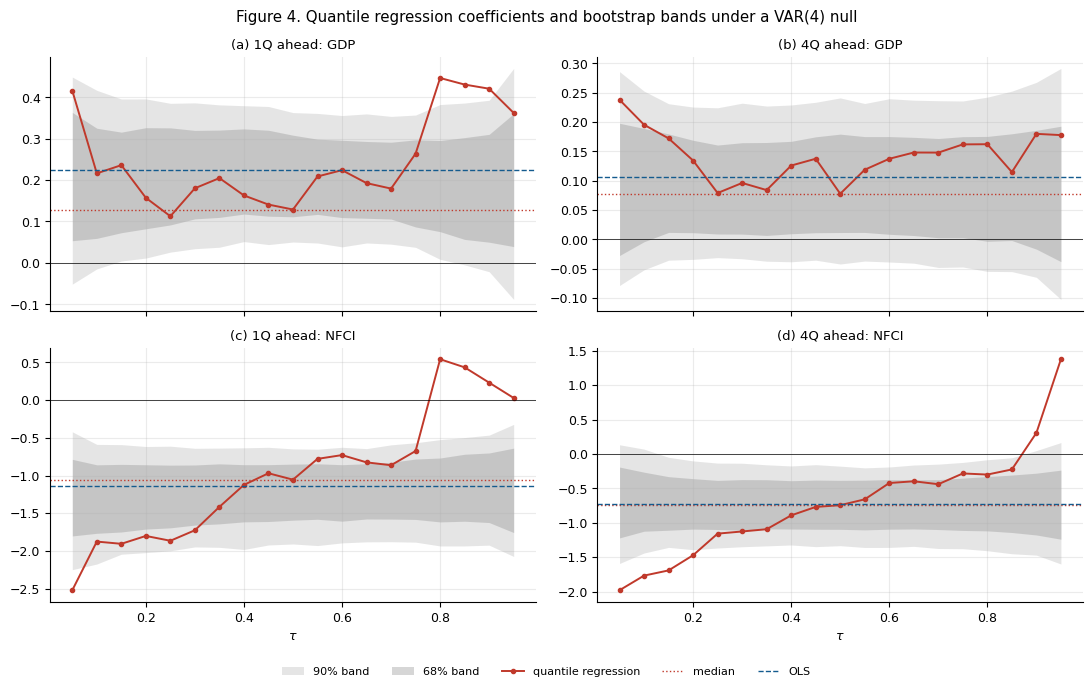

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
for col, h in enumerate(H):
    for row, (j, name) in enumerate([(1, "GDP"), (2, "NFCI")]):
        ax = axes[row, col]
        lo90, lo68, hi68, hi90 = np.percentile(BOOT[h][:, :, j], [5, 16, 84, 95], axis=0)
        ax.fill_between(QQ, lo90, hi90, color=GREY, alpha=0.22, lw=0, label="90% band")
        ax.fill_between(QQ, lo68, hi68, color=GREY, alpha=0.35, lw=0, label="68% band")
        ax.plot(QQ, B[h][:, j], "o-", color=RED, ms=3, label="quantile regression")
        ax.axhline(B[h][jq(.5), j], color=RED, ls=":", lw=1, label="median")
        ax.axhline(OLS[h][j], color=BLUE, ls="--", lw=1, label="OLS")
        ax.axhline(0, color="k", lw=0.5)
        ax.set_title(f"({'ab'[col] if row == 0 else 'cd'[col]}) {'1Q' if h == 1 else '4Q'} ahead: {name}")
        if row == 1: ax.set_xlabel(r"$\tau$")
fig.suptitle("Figure 4. Quantile regression coefficients and bootstrap bands under a VAR(4) null")
fig.tight_layout(); legend_below(fig, axes[0, 0]); save(fig, "fig04_coefficients.png"); plt.show()

The figure reproduces the paper's message.
- The **NFCI** coefficient rises with $\tau$, from about $-2.5$ (h=1) and $-2.0$ (h=4) at the 5th percentile to around zero or above at the top. It leaves the 90% bands of the linear Gaussian null at both ends: in 5 of the 19 quantiles for $h=1$ (the 5th percentile and $\tau\ge 0.80$) and 6 for $h=4$ (at both ends of the distribution). No linear Gaussian VAR generates a dependence of the quantiles on financial conditions this asymmetric.
- The **GDP** coefficients are inside the bands everywhere at $h=4$ and in all but three quantiles at $h=1$ (around $\tau = 0.80$–0.90): current growth moves the distribution roughly in parallel.

## 5. Figures 5 and 6: predicted quantiles over time

The coefficients $\hat\beta_\tau$ are estimated once, on the full sample, and are fixed. The **predicted quantiles** change every quarter because the predictors do:

$$\hat Q(\tau\mid x_t) = \underbrace{\hat\alpha_\tau}_{\text{fixed}} + \underbrace{\hat\beta^{GDP}_\tau}_{\text{fixed}}\,\underbrace{\mathrm{GDP}_t}_{\text{varies}} + \underbrace{\hat\beta^{NFCI}_\tau}_{\text{fixed}}\,\underbrace{\mathrm{NFCI}_t}_{\text{varies}} .$$

**Figure 5** plots, for each target quarter $t+h$, the predicted median, the 25–75 and 5–95 ranges, and realised growth. Because $\hat\beta^{NFCI}_{0.05}$ is far more negative than $\hat\beta^{NFCI}_{0.95}$, a jump in the NFCI pulls the lower edge of the fan down much more than the upper edge.

**Figure 6** summarises the same predictions with three numbers per quarter: the median, the interquartile range $IQR_t = \hat Q(0.75\mid x_t) - \hat Q(0.25\mid x_t)$ (a measure of uncertainty), and the 5th percentile (Growth-at-Risk). Expanding the IQR,

$$IQR_t = (\hat\alpha_{0.75}-\hat\alpha_{0.25}) + (\hat\beta^{GDP}_{0.75}-\hat\beta^{GDP}_{0.25})\,\mathrm{GDP}_t + (\hat\beta^{NFCI}_{0.75}-\hat\beta^{NFCI}_{0.25})\,\mathrm{NFCI}_t ,$$

the term in the NFCI is positive whenever the NFCI coefficient rises with $\tau$: tighter financial conditions widen the distribution. The same NFCI lowers the median (because $\hat\beta^{NFCI}_{0.50} < 0$) and lowers the 5th percentile by more still. So uncertainty and downside risk move together, and the 5th percentile falls faster than the median when the IQR rises.

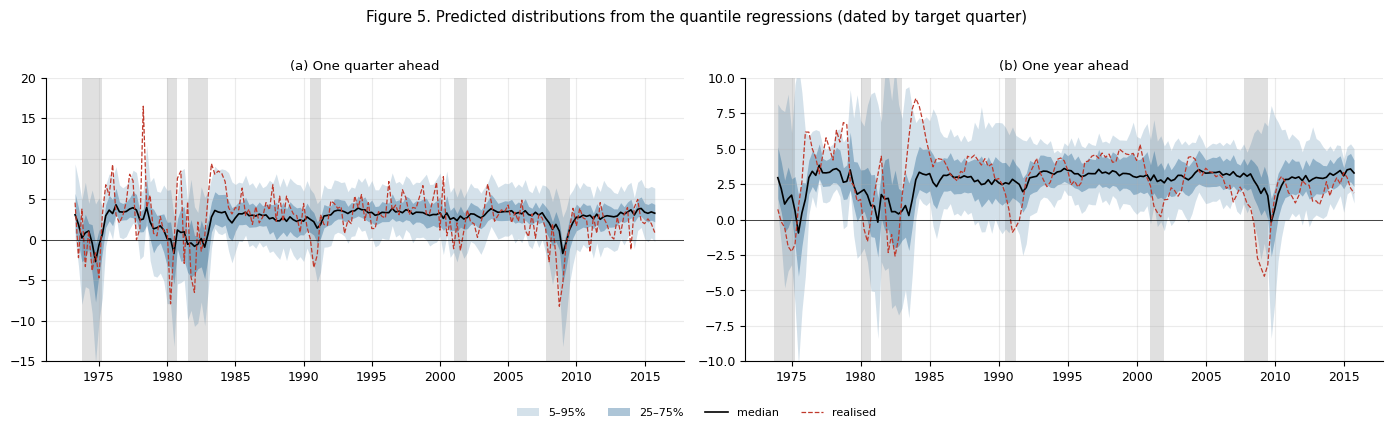

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, h in zip(axes, H):
    shade(ax)
    q = YQ[h]
    ax.fill_between(TDATE[h], q[:, jq(.05)], q[:, jq(.95)], color=BLUE, alpha=0.18, lw=0, label="5–95%")
    ax.fill_between(TDATE[h], q[:, jq(.25)], q[:, jq(.75)], color=BLUE, alpha=0.35, lw=0, label="25–75%")
    ax.plot(TDATE[h], q[:, jq(.5)], color="k", lw=1.2, label="median")
    ax.plot(TDATE[h], Y[h], color=RED, lw=0.9, ls="--", label="realised")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylim(-15, 20) if h == 1 else ax.set_ylim(-10, 10)
    ax.set_title(f"({'ab'[H.index(h)]}) {'One quarter' if h == 1 else 'One year'} ahead"); time_axis(ax)
fig.suptitle("Figure 5. Predicted distributions from the quantile regressions (dated by target quarter)", y=1.02)
fig.tight_layout(); legend_below(fig, axes[0]); save(fig, "fig05_predicted_quantiles.png"); plt.show()

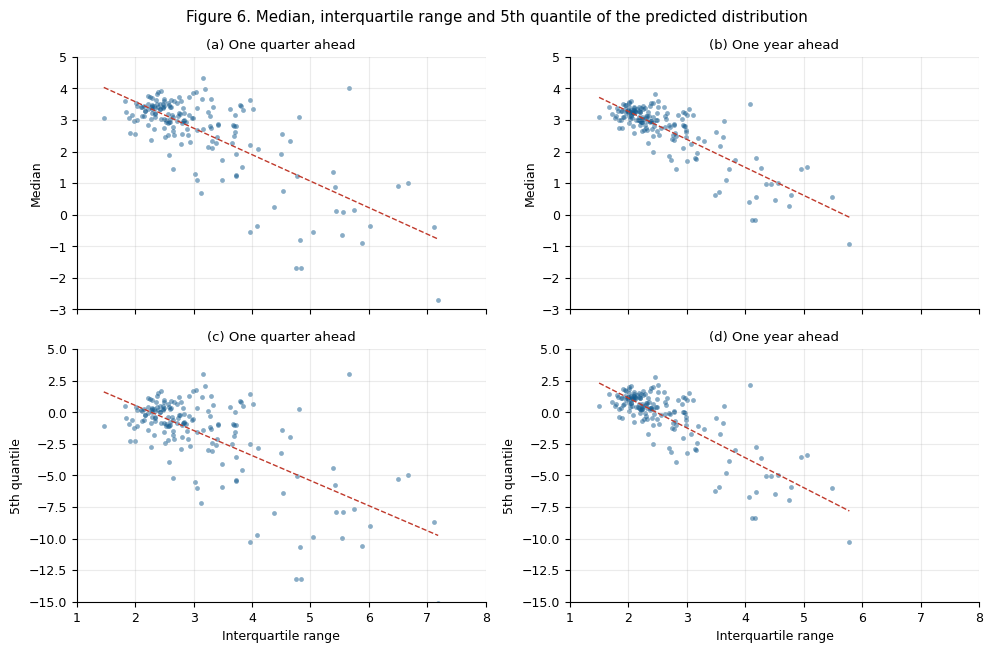

corr with IQR  slope on IQR
h=1 Median                -0.73         -0.84
    5th quantile          -0.67         -1.99
h=4 Median                -0.83         -0.89
    5th quantile          -0.81         -2.37

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex=True)
rows = {}
for col, h in enumerate(H):
    q = YQ[h]
    iqr, med, q05 = q[:, jq(.75)] - q[:, jq(.25)], q[:, jq(.5)], q[:, jq(.05)]
    for row, (v, name) in enumerate([(med, "Median"), (q05, "5th quantile")]):
        ax = axes[row, col]
        slope, icpt = np.polyfit(iqr, v, 1)
        ax.scatter(iqr, v, s=12, color=BLUE, alpha=0.5, lw=0)
        xs = np.linspace(iqr.min(), iqr.max(), 50); ax.plot(xs, icpt + slope * xs, color=RED, ls="--", lw=1)
        ax.set_xlim(1, 8); ax.set_ylim((-3, 5) if row == 0 else (-15, 5))
        ax.set_title(f"({'abcd'[2 * row + col]}) {'One quarter' if h == 1 else 'One year'} ahead")
        ax.set_ylabel(name)
        if row == 1: ax.set_xlabel("Interquartile range")
        rows[(f"h={h}", name)] = {"corr with IQR": np.corrcoef(iqr, v)[0, 1], "slope on IQR": slope}
fig.suptitle("Figure 6. Median, interquartile range and 5th quantile of the predicted distribution")
fig.tight_layout(); save(fig, "fig06_median_iqr_q05.png"); plt.show()
pd.DataFrame(rows).T.round(2)

In Figure 5 the lower edge of the fan plunges in every recession (1974–75, 1980–82, 2008–09), while the upper edge moves much less. Figure 6 confirms that uncertainty and downside risk move together. Both the median and the 5th quantile fall as the IQR widens. The **slope** of the 5th quantile on the IQR ($-1.99$ at $h=1$, $-2.37$ at $h=4$) is more than twice that of the median ($-0.84$, $-0.89$): a wider distribution comes with a much lower left tail. The *correlations* are similar (about $-0.7$ to $-0.8$ for both) and the one for the 5th quantile is slightly weaker, so the asymmetry is in how much the two quantiles move, not in how tightly they co-move with the IQR.

## 6. The skewed $t$-distribution

### From four quantiles to a density

Each quarter the quantile regressions deliver points on the conditional **quantile function** $F^{-1}(\tau)$, not a density. To ask questions such as *"what is the probability that growth falls below $-2\%$?"* we need a continuous density $f_t(y)$, its CDF $F_t(y) = \int_{-\infty}^y f_t(z)\,dz$, and the quantile function $F_t^{-1}(\tau) = \inf\{y: F_t(y)\ge\tau\}$. Quantile regression estimates $F^{-1}$ directly; the fitting step goes the other way and recovers a parametric $f$ that reproduces the estimated quantiles.

Four quantiles do not pin down a distribution: something has to say what happens between them and in the tails. A free-form interpolation (for example a monotone spline through the four points) would fit them exactly, but its shape between the points and its tails beyond $Q_{0.05}$ and $Q_{0.95}$ would be arbitrary, and the tails are exactly what Growth-at-Risk is about. A parametric family with four parameters fits four quantiles, has tails governed by a parameter rather than by extrapolation, and gives a density in closed form.

### The skewed $t$ of Azzalini and Capitanio (2003)

The paper uses the skewed $t$-distribution, which allows for both fat tails and asymmetry, two features documented for macroeconomic data:

$$f(y;\mu,\sigma,\alpha,\nu) = \frac{2}{\sigma}\;\underbrace{t\!\left(\frac{y-\mu}{\sigma};\nu\right)}_{\text{symmetric } t \text{ density}}\;\underbrace{T\!\left(\alpha\,\frac{y-\mu}{\sigma}\sqrt{\frac{\nu+1}{\nu+\left(\frac{y-\mu}{\sigma}\right)^2}};\ \nu+1\right)}_{\text{skewing factor}}$$

where $t(\cdot;\nu)$ is the density and $T(\cdot;\nu+1)$ the CDF of a Student $t$.
- **$\mu$, location:** shifts the distribution; it is the mean only when $\alpha = 0$.
- **$\sigma > 0$, scale:** stretches it; larger $\sigma$ means more uncertainty.
- **$\alpha$, shape:** the asymmetry. $\alpha<0$ gives a longer left tail, $\alpha>0$ a longer right tail, and $\alpha=0$ the symmetric $t$ (the skewing factor is then $T(0) = 1/2$, which the factor 2 cancels).
- **$\nu > 0$, degrees of freedom:** tail thickness. Small $\nu$ means fat tails; $\nu\to\infty$ gives Gaussian tails.

| condition | distribution |
|---|---|
| $\alpha = 0$ | Student $t$: fat tails, symmetric (as in models with $t$-distributed shocks, e.g. Antolín-Díaz, Drechsel and Petrella, 2024) |
| $\alpha = 0,\ \nu\to\infty$ | Gaussian $\mathcal N(\mu,\sigma^2)$ |
| $\nu\to\infty,\ \alpha\ne 0$ | skew-normal (Azzalini, 1985) |

### Matching the quantiles: four equations, four unknowns

For each quarter, the parameters solve

$$\{\hat\mu_t,\hat\sigma_t,\hat\alpha_t,\hat\nu_t\} = \arg\min_{\mu,\sigma,\alpha,\nu}\ \sum_{\tau\in\{0.05,\,0.25,\,0.75,\,0.95\}}\Big(\hat Q(\tau\mid x_t) - F^{-1}(\tau;\mu,\sigma,\alpha,\nu)\Big)^2 ,$$

four equations in four unknowns. Intuitively, $\mu$ moves all quantiles together, $\sigma$ spreads them around $\mu$, $\alpha$ moves the low quantiles further than the high ones, and $\nu$ controls how far the extreme quantiles (5th and 95th) are from the central ones. As in the paper, $\nu$ is restricted to the integers $1,\dots,30$, $\alpha$ to $[-30, 30]$, $\mu$ to $[-20,20]$ and $\sigma$ to $(0, 50]$, so an exact fit is not always attainable.

**How we solve it.** $F^{-1}$ has no closed form, but the skewed $t$ is a location-scale family: $F^{-1}(\tau;\mu,\sigma,\alpha,\nu) = \mu + \sigma\,q(\tau;\alpha,\nu)$, where $q$ is the quantile function of the standardised distribution. For given $(\alpha,\nu)$ the problem is therefore an ordinary least-squares regression of the four target quantiles on $[1,\ q(\tau;\alpha,\nu)]$, which gives $\mu$ and $\sigma$ in closed form. What remains is a search over $\nu\in\{1,\dots,30\}$ and $\alpha\in[-30,30]$: a grid first, then a one-dimensional refinement of $\alpha$.

**Computing $F$ and $F^{-1}$.** The CDF is integrated numerically after the change of variable $z = \tan\theta$, which maps the real line onto $(-\pi/2, \pi/2)$ and keeps the integrand bounded even for $\nu = 1$ (Cauchy-like tails). The quantile function is obtained by inverting this CDF. Both are accurate to about $10^{-6}$: below, the CDF is checked against an adaptive numerical integration of the density, and the quantiles against the Student $t$ for $\alpha = 0$.

In [11]:
def dskt(y, loc=0.0, scale=1.0, shape=0.0, df=5.0):
    """Density of the Azzalini-Capitanio skewed t."""
    z = (np.asarray(y, float) - loc) / scale
    w = shape * z * np.sqrt((df + 1) / (df + z**2))
    return 2 / scale * stats.t.pdf(z, df) * stats.t.cdf(w, df + 1)

def _std_cdf(shape, df, n=4000):
    """CDF of the standardised skewed t on the grid z = tan(theta). One row per value of shape."""
    h = np.pi / n
    th = -np.pi / 2 + h * (np.arange(n) + 0.5)                     # midpoints
    shape = np.atleast_1d(np.asarray(shape, float))[:, None]
    g = dskt(np.tan(th)[None, :], 0, 1, shape, df) / np.cos(th) ** 2
    F = np.concatenate([np.zeros((len(shape), 1)), np.cumsum(g, axis=1) * h], axis=1)
    return -np.pi / 2 + h * np.arange(n + 1), F / F[:, -1:]

def _std_q(tau, shape, df, n=4000):
    th, F = _std_cdf(shape, df, n)
    return np.array([np.tan(np.interp(np.atleast_1d(tau), Fi, th)) for Fi in F])

def qskt(tau, loc, scale, shape, df):
    """Quantile function."""
    return loc + scale * _std_q(tau, shape, df)[0]

def pskt(y, loc, scale, shape, df):
    """CDF."""
    th, F = _std_cdf(shape, df)
    return np.interp(np.arctan((np.asarray(y, float) - loc) / scale), th, F[0])

DF_GRID, SHAPES = np.arange(1, 31), np.linspace(-30, 30, 1201)

@lru_cache(maxsize=None)
def _q_table():
    """standardised quantiles at TAU_FIT for every (df, shape) on the grid: (30, 1201, 4)"""
    return np.stack([_std_q(TAU_FIT, SHAPES, df, n=2000) for df in DF_GRID])

def _ls(q, x):
    """least squares of q on [1, x] along the last axis -> loc, scale, sum of squared errors"""
    xm, qm = x.mean(-1, keepdims=True), q.mean()
    sc = ((x - xm) * (q - qm)).sum(-1) / ((x - xm) ** 2).sum(-1)
    lc = qm - sc * xm[..., 0]
    return lc, sc, ((q - lc[..., None] - sc[..., None] * x) ** 2).sum(-1)

def fit_skt(q):
    """Fit the skewed t to target quantiles q at TAU_FIT. Returns ([loc, scale, shape, df], SSE)."""
    q = np.asarray(q, float)
    lc, sc, sse = _ls(q, _q_table())
    sse = np.where((sc > 0) & (sc <= 50) & (np.abs(lc) <= 20), sse, np.inf)
    i_df, i_sh = np.unravel_index(np.argmin(sse), sse.shape)
    df, step = DF_GRID[i_df], SHAPES[1] - SHAPES[0]
    a = optimize.minimize_scalar(lambda a: _ls(q, _std_q(TAU_FIT, a, df))[2][0],
                                 bounds=(max(SHAPES[i_sh] - step, -30), min(SHAPES[i_sh] + step, 30)),
                                 method="bounded", options={"xatol": 1e-6}).x
    lc, sc, sse = _ls(q, _std_q(TAU_FIT, a, df))
    return np.array([lc[0], sc[0], a, df]), sse[0]

# ---- checks ----
from scipy import integrate

def cdf_reference(y, *p):
    """independent check: adaptive integration of the density"""
    f = lambda u: float(dskt(u, *p))
    return integrate.quad(f, -np.inf, -50)[0] + integrate.quad(f, -50, y, limit=500)[0]

taus = np.array([0.05, 0.25, 0.50, 0.75, 0.95])
cases = [(-3.0, (0, 1, -2, 5)), (0.5, (0, 1, -2, 5)), (2.0, (1, 2, 4, 3)), (-6.0, (0, 1, -30, 2)), (1.0, (0, 1, 0, 1))]
checks = {
    "quantiles with alpha=0 vs Student t (df=1, 5, 30)": max(np.abs(qskt(taus, 0, 1, 0, d) - stats.t.ppf(taus, d)).max() for d in [1, 5, 30]),
    "CDF vs adaptive integration of the density (5 cases)": max(abs(pskt(y, *p) - cdf_reference(y, *p)) for y, p in cases),
    "density integrates to 1 (alpha=4, df=3)": abs(np.trapezoid(dskt(np.linspace(-400, 400, 400001), 0, 1, 4, 3),
                                                               np.linspace(-400, 400, 400001)) - 1),
}
t0 = time.time(); _q_table(); print(f"quantile table built in {time.time() - t0:.0f}s")
pd.Series(checks, name="max abs error").map("{:.1e}".format)

quantile table built in 19s


quantiles with alpha=0 vs Student t (df=1, 5, 30)       7.1e-07
CDF vs adaptive integration of the density (5 cases)    1.1e-07
density integrates to 1 (alpha=4, df=3)                 3.4e-08
Name: max abs error, dtype: str

### How the four parameters shape the distribution

The figure below changes one parameter at a time around $\mu = 2,\ \sigma = 2,\ \alpha = -1,\ \nu = 5$, values typical of the fitted distributions. The table reports what happens to the moments and to three quantiles as $\alpha$ varies.

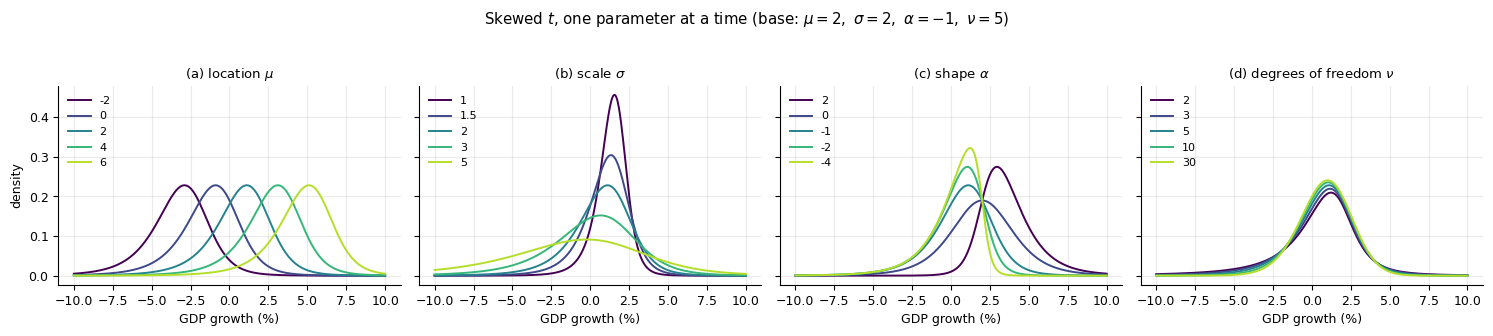

,mean,std. dev.,skewness,Q05,Q50,Q95
alpha,,,,,,
2,3.70,1.95,1.79,1.26,3.39,7.14
1,3.34,2.21,1.07,0.25,3.15,7.06
0,2.00,2.58,-0.00,-2.03,2.00,6.03
-1,0.66,2.21,-1.07,-3.06,0.85,3.75
-2,0.30,1.95,-1.79,-3.14,0.61,2.74
-4,0.16,1.81,-2.28,-3.14,0.55,2.17


In [12]:
def moments(f, yy):
    """mean, variance, skewness and kurtosis of a density evaluated on the grid yy"""
    dy = yy[1] - yy[0]
    m = np.sum(yy * f) * dy
    v = np.sum((yy - m) ** 2 * f) * dy
    return m, v, np.sum((yy - m) ** 3 * f) * dy / v**1.5, np.sum((yy - m) ** 4 * f) * dy / v**2

BASE = dict(loc=2.0, scale=2.0, shape=-1.0, df=5)
yy = np.linspace(-10, 10, 500)
VARY = [("loc", [-2, 0, 2, 4, 6], r"(a) location $\mu$"), ("scale", [1, 1.5, 2, 3, 5], r"(b) scale $\sigma$"),
        ("shape", [2, 0, -1, -2, -4], r"(c) shape $\alpha$"), ("df", [2, 3, 5, 10, 30], r"(d) degrees of freedom $\nu$")]
cmap = plt.get_cmap("viridis")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (par, vals, title) in zip(axes, VARY):
    for i, v in enumerate(vals):
        ax.plot(yy, dskt(yy, **{**BASE, par: v}), color=cmap(i / 4.5), label=f"{v}")
    ax.set_title(title); ax.legend(loc="upper left"); ax.set_xlabel("GDP growth (%)")
axes[0].set_ylabel("density")
fig.suptitle(r"Skewed $t$, one parameter at a time (base: $\mu=2,\ \sigma=2,\ \alpha=-1,\ \nu=5$)", y=1.03)
fig.tight_layout(); save(fig, "skewed_t_parameters.png"); plt.show()

wide = np.linspace(-200, 200, 400001)
tab = {}
for a in [2, 1, 0, -1, -2, -4]:
    p = {**BASE, "shape": a}
    m, v, s, _ = moments(dskt(wide, **p), wide)
    q05, q50, q95 = qskt([0.05, 0.5, 0.95], *p.values())
    tab[a] = {"mean": m, "std. dev.": np.sqrt(v), "skewness": s, "Q05": q05, "Q50": q50, "Q95": q95}
pd.DataFrame(tab).T.rename_axis("alpha").round(2)

**What $\alpha$ does, with $\mu$, $\sigma$ and $\nu$ fixed.** Moving $\alpha$ from 0 to $-4$:
- the **mean** falls from 2.00 to 0.16, even though the location parameter stays at 2. $\mu$ is not the mean when $\alpha\ne 0$;
- the **standard deviation falls** (from 2.58 to 1.81): a more skewed distribution with the same scale is *less* dispersed, because the side opposite to the skew is compressed against $\mu$;
- the **skewness** goes from 0 to $-2.28$;
- all quantiles move down. The 5th falls from $-2.03$ to $-3.14$, but the median (from 2.00 to 0.55) and above all the 95th percentile (from 6.03 to 2.17) fall more: with $\mu$ fixed, a negative $\alpha$ mostly removes the right tail.

The effects saturate beyond $|\alpha|\approx 4$, as the distribution approaches a half-$t$. This is why large values of $|\alpha|$ are poorly identified by four quantiles, and why the fitted $\alpha$ sometimes jumps to its bound of $\pm 30$ (section 10).

## 7. Fitting the skewed $t$ every quarter

Each quarter we take the four predicted quantiles $[\hat Q_{0.05}, \hat Q_{0.25}, \hat Q_{0.75}, \hat Q_{0.95}]$ and fit a skewed $t$: 171 distributions for $h = 1$ and 168 for $h = 4$. We do this for the main model (GDP and NFCI), for the model with GDP only, and once for the **unconditional** distribution, whose quantiles come from a quantile regression on a constant alone (i.e. the sample quantiles of $y_{t+h}$).

In [13]:
def fit_rows(Q):
    out = [fit_skt(q) for q in Q]
    return np.array([p for p, _ in out]), np.array([s for _, s in out])

ITF = [jq(t) for t in TAU_FIT]
t0 = time.time()
ST, SSE, STG, SSEG, STU = {}, {}, {}, {}, {}
for h in H:
    ST[h], SSE[h] = fit_rows(YQ[h][:, ITF])                                # GDP + NFCI
    STG[h], SSEG[h] = fit_rows(YQG[h][:, ITF])                             # GDP only
    STU[h] = fit_skt(qreg(Y[h], np.ones((len(Y[h]), 1)), TAU_FIT)[:, 0])[0]  # unconditional
print(f"{2 * (len(Y[1]) + len(Y[4])) + 2} skewed-t fits in {time.time() - t0:.0f}s")

pd.DataFrame({(f"h={h}", m): {"df = 30 (upper bound)": np.mean(P[:, 3] == 30), "df <= 5": np.mean(P[:, 3] <= 5),
                              "median df": np.median(P[:, 3]), "|shape| = 30 (bound)": np.mean(np.abs(P[:, 2]) >= 29.99),
                              "SSE < 0.001": np.mean(S < 1e-3), "max SSE": S.max()}
              for h in H for m, P, S in [("GDP+NFCI", ST[h], SSE[h]), ("GDP only", STG[h], SSEG[h])]}).round(3)

680 skewed-t fits in 21s


h=1               h=4         
                      GDP+NFCI GDP only GDP+NFCI GDP only
df = 30 (upper bound)    0.263    0.082    0.667    0.000
df <= 5                  0.462    0.678    0.220    0.964
median df                6.000    5.000   30.000    2.000
|shape| = 30 (bound)     0.029    0.000    0.012    0.006
SSE < 0.001              0.556    0.655    0.226    0.339
max SSE                  3.074    0.416    0.661    0.310

### How good is the fit?

For each quarter and each matched quantile, the fitting error is $e_{t,i} = \hat Q_{\tau_i}^{\text{target}} - F^{-1}(\tau_i;\hat\mu_t,\hat\sigma_t,\hat\alpha_t,\hat\nu_t)$. We summarise it by the mean absolute error, the root mean squared error, and the MAE relative to the average interquartile range of the targets.

Q05   Q25   Q75   Q95
h=1 GDP only  0.26  0.77  0.78  0.27
    GDP+NFCI  0.71  1.81  1.80  0.70
h=4 GDP only  0.61  2.15  2.22  0.68
    GDP+NFCI  1.51  4.05  4.25  1.71

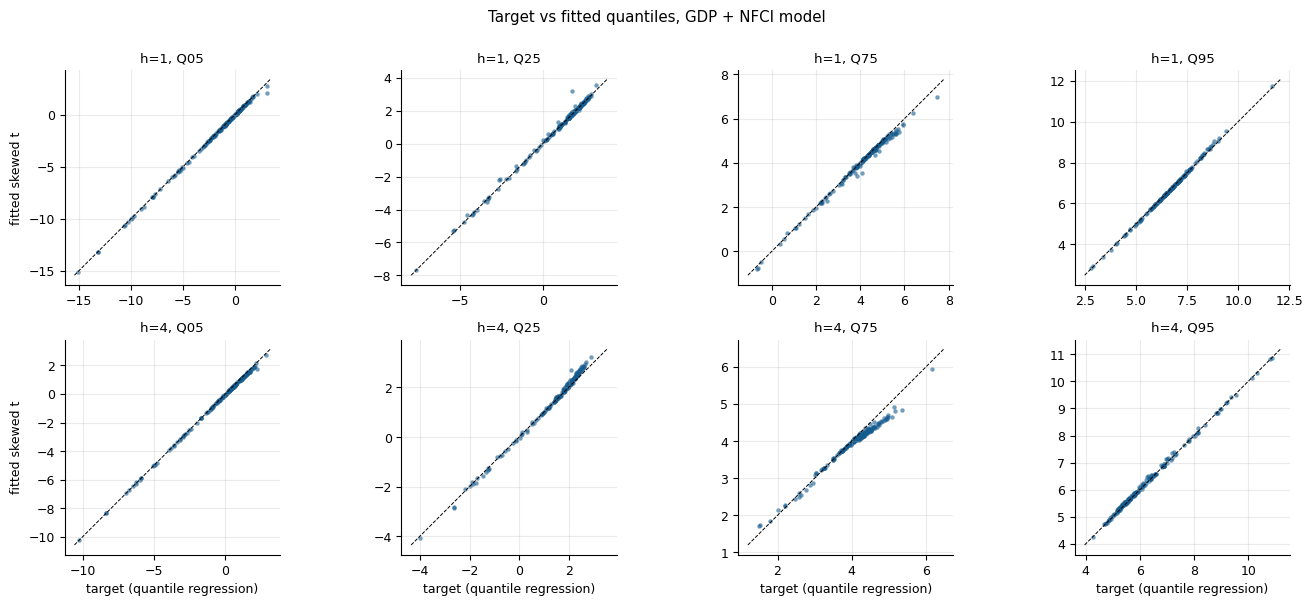

In [14]:
def fitted_q(P, taus):
    return np.array([qskt(taus, *p) for p in P])

QFIT = {(h, m): fitted_q(P, TAU_FIT) for h in H for m, P in [("GDP+NFCI", ST[h]), ("GDP only", STG[h])]}
QTGT = {(h, m): Q[:, ITF] for h in H for m, Q in [("GDP+NFCI", YQ[h]), ("GDP only", YQG[h])]}
rows = {}
for key in QFIT:
    e = QTGT[key] - QFIT[key]
    iqr = np.mean(QTGT[key][:, 2] - QTGT[key][:, 1])
    for i, t in enumerate(TAU_FIT):
        rows[(f"h={key[0]}", key[1], f"Q{int(t * 100):02d}")] = {
            "MAE": np.abs(e[:, i]).mean(), "RMSE": np.sqrt((e[:, i] ** 2).mean()), "MAE / IQR (%)": 100 * np.abs(e[:, i]).mean() / iqr}
err = pd.DataFrame(rows).T
display(err.unstack(level=2).xs("MAE / IQR (%)", axis=1, level=0).round(2))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for row, h in enumerate(H):
    for i, t in enumerate(TAU_FIT):
        ax = axes[row, i]
        x, y = QTGT[(h, "GDP+NFCI")][:, i], QFIT[(h, "GDP+NFCI")][:, i]
        ax.scatter(x, y, s=10, color=BLUE, alpha=0.6, lw=0)
        lim = [min(x.min(), y.min()) - 0.3, max(x.max(), y.max()) + 0.3]
        ax.plot(lim, lim, color="k", lw=0.7, ls="--")
        ax.set_title(f"h={h}, Q{int(t * 100):02d}"); ax.set_aspect("equal")
        if row == 1: ax.set_xlabel("target (quantile regression)")
        if i == 0: ax.set_ylabel("fitted skewed t")
fig.suptitle("Target vs fitted quantiles, GDP + NFCI model", y=1.0)
fig.tight_layout(); save(fig, "fit_target_vs_fitted.png"); plt.show()

**The degrees of freedom now vary.** For the main model the median $\hat\nu$ is 6 at $h=1$. It is at most 5 in 46% of quarters and hits the upper bound of 30 in 26%. At $h=4$ it is at 30 in two thirds of the quarters: these distributions are close to a skew-normal. The GDP-only model needs fatter tails (median $\hat\nu = 5$ at $h=1$ and 2 at $h=4$). We checked the fitted parameters separately against the authors' replication files: $\hat\nu$ is the same in 96% of quarters at $h=1$ and 99% at $h=4$, and location and scale differ by less than 0.1.

**The fit is good but not exact.** With $\nu$ integer and the parameters bounded, four quantiles cannot always be matched. The sum of squared errors is below 0.001 in 56% of quarters at $h=1$ and in 23% at $h=4$, and the mean absolute error is 0.7–1.8% of the average IQR at $h=1$ and 1.5–4.3% at $h=4$. Errors are two to three times larger at the 25th and 75th percentiles than at the 5th and 95th, so the fitted distributions are most accurate in the tails, which are what matters for Growth-at-Risk. The GDP-only targets are smoother and are matched more closely.

## 8. Figure 1 and Figures 7–8: the predictive densities

**Figure 1** stacks the fitted densities over time (dated by target quarter). **Figures 7 and 8** zoom on three conditioning quarters: a calm one (2006Q2), the trough of the financial crisis (2008Q4), and the recovery (2014Q4). Figure 7 compares the quantile function of the fitted skewed $t$ with the 19 "raw" quantiles from the regression; Figure 8 compares the densities of the full model and the GDP-only model.

Figure 1 is shown twice: as a static image and as an interactive Plotly surface (rotate, zoom and hover to read the density of any quarter), which is also saved to `figures/gdp_distribution_3d.html`.

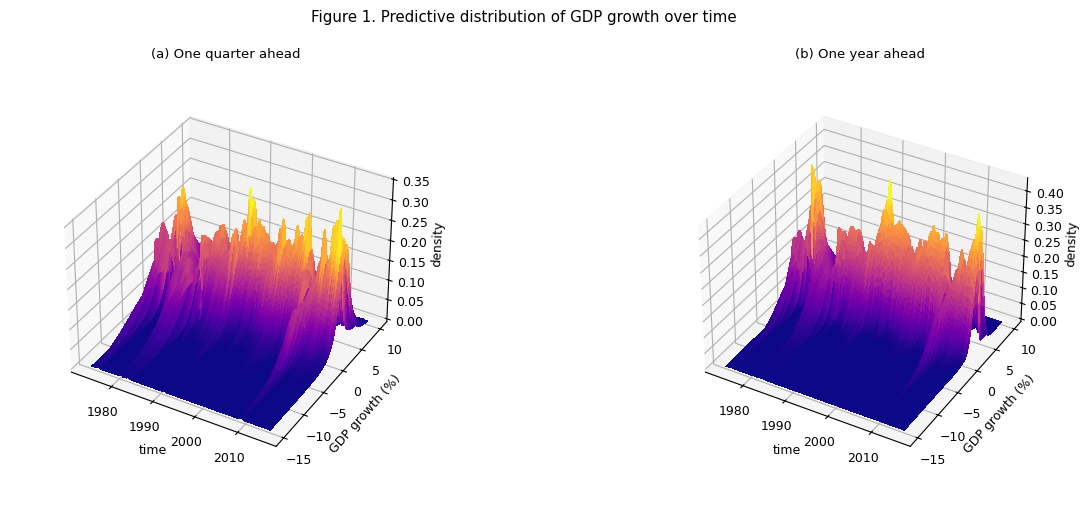

In [15]:
YY = np.round(np.arange(-20, 20.0001, 0.05), 4)       # evaluation grid for densities
DENS = {h: np.array([dskt(YY, *p) for p in ST[h]]) for h in H}

fig = plt.figure(figsize=(15, 5.6))
for k, h in enumerate(H):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    sel = (YY >= -15) & (YY <= 10)
    tnum = TDATE[h].year + (TDATE[h].month - 1) / 12
    TT, GG = np.meshgrid(tnum, YY[sel], indexing="ij")
    ax.plot_surface(TT, GG, DENS[h][:, sel], cmap="plasma", rstride=1, cstride=4, linewidth=0, antialiased=False)
    ax.view_init(elev=35, azim=-60); ax.set_box_aspect(None, zoom=0.85)
    ax.set_xlabel("time"); ax.set_ylabel("GDP growth (%)"); ax.set_zlabel("density")
    ax.set_title(f"({'ab'[k]}) {'One quarter' if h == 1 else 'One year'} ahead")
fig.suptitle("Figure 1. Predictive distribution of GDP growth over time", y=0.98)
save(fig, "fig01_density_3d.png"); plt.show()

# interactive version (shown below and saved to figures/)
import plotly.graph_objects as go
from plotly.subplots import make_subplots
pfig = make_subplots(rows=2, cols=1, specs=[[{"type": "surface"}], [{"type": "surface"}]],
                     subplot_titles=["One quarter ahead", "One year ahead"], vertical_spacing=0.04)
for k, h in enumerate(H):
    sel = (YY >= -15) & (YY <= 10)
    sel[np.flatnonzero(sel)[1::2]] = False                     # every other point: 0.1 grid
    pfig.add_trace(go.Surface(x=YY[sel], y=TDATE[h], z=DENS[h][:, sel], colorscale="Plasma",
                              showscale=False), row=k + 1, col=1)
pfig.update_scenes(xaxis_title="GDP growth (%)", yaxis_title="", zaxis_title="density")
pfig.update_layout(title="Predictive distribution of GDP growth (Adrian, Boyarchenko and Giannone, 2019)",
                   height=1100, autosize=True, margin=dict(l=0, r=0, t=60, b=0))
pfig.write_html(FIG / "gdp_distribution_3d.html", include_plotlyjs="cdn", config={"responsive": True})
pfig.show(renderer="notebook_connected", config={"responsive": True})   # interactive: rotate, zoom, hover

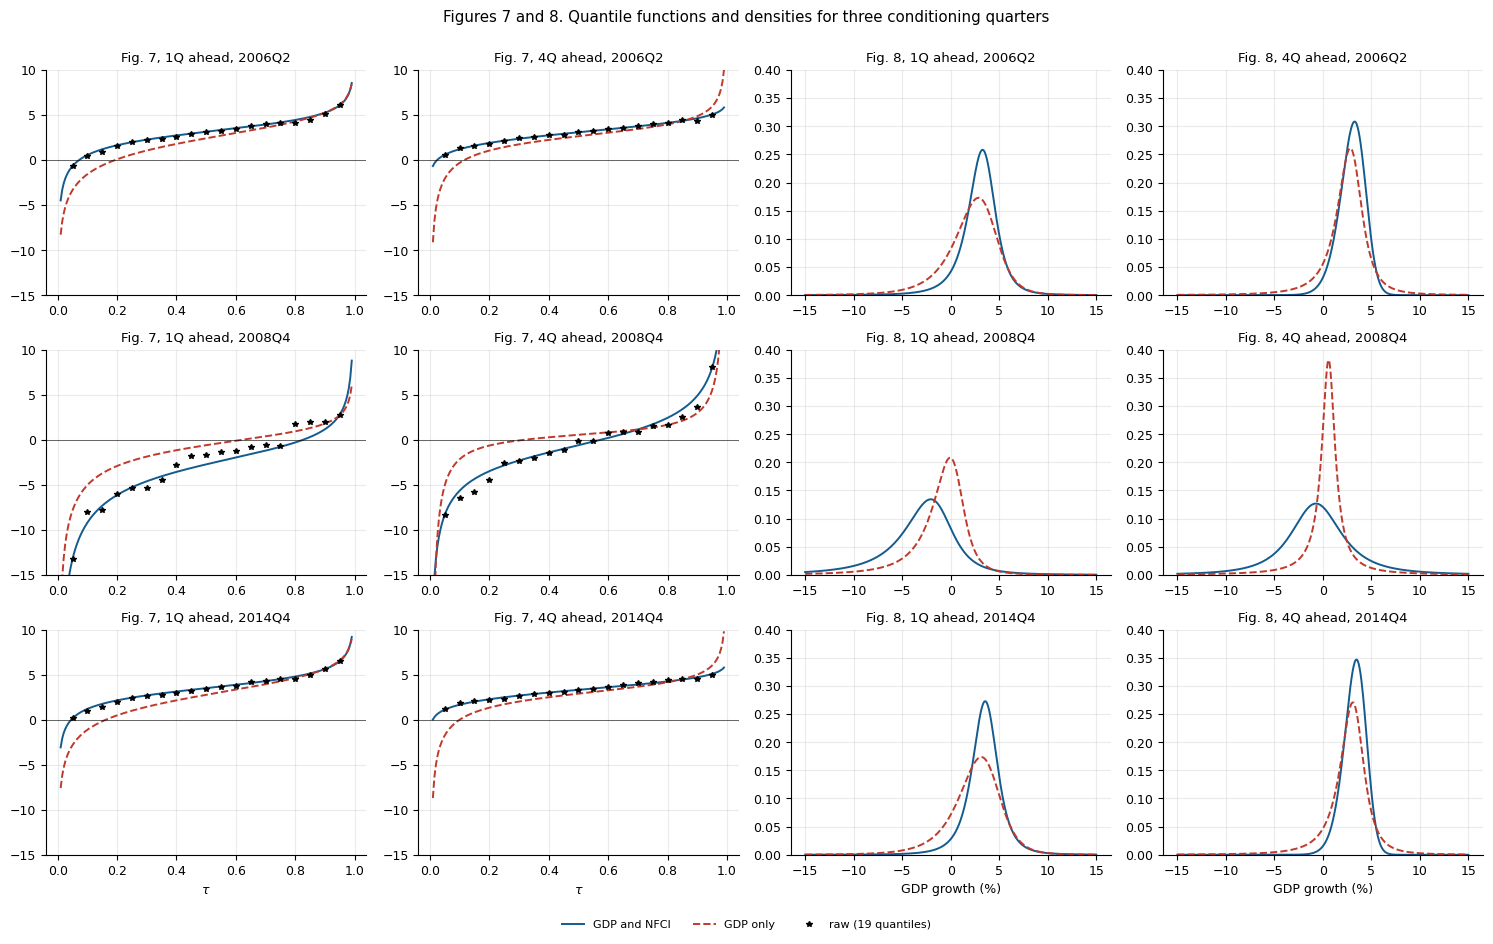

location  scale  shape    df
2006Q2 h=1 GDP+NFCI      3.72   1.52  -0.51   3.0
           GDP only      4.10   2.71  -1.19   4.0
       h=4 GDP+NFCI      4.21   1.78  -1.59  30.0
           GDP only      3.18   1.43  -0.47   2.0
2008Q4 h=1 GDP+NFCI     -0.92   3.05  -0.90   2.0
           GDP only      0.79   2.09  -1.17   2.0
       h=4 GDP+NFCI     -0.95   2.80   0.14   2.0
           GDP only      0.62   0.83  -0.08   1.0
2014Q4 h=1 GDP+NFCI      3.74   1.36  -0.21   3.0
           GDP only      4.30   2.61  -1.04   4.0
       h=4 GDP+NFCI      4.29   1.55  -1.50  30.0
           GDP only      3.45   1.39  -0.51   2.0

In [16]:
SNAP = {"2006Q2": "2006-04-01", "2008Q4": "2008-10-01", "2014Q4": "2014-10-01"}
tgrid = np.linspace(0.01, 0.99, 197)
xg = np.linspace(-15, 15, 600)
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for r, (lab, d) in enumerate(SNAP.items()):
    for k, h in enumerate(H):
        i = CDATE[h].get_loc(pd.Timestamp(d))
        ax = axes[r, k]                                     # Figure 7: quantile functions
        ax.plot(tgrid, qskt(tgrid, *ST[h][i]), color=BLUE, label="GDP and NFCI")
        ax.plot(tgrid, qskt(tgrid, *STG[h][i]), color=RED, ls="--", label="GDP only")
        ax.plot(QQ, YQ[h][i], "*", color="k", ms=4, label="raw (19 quantiles)")
        ax.set_ylim(-15, 10); ax.axhline(0, color="k", lw=0.4)
        ax.set_title(f"Fig. 7, {'1Q' if h == 1 else '4Q'} ahead, {lab}")
        ax = axes[r, 2 + k]                                 # Figure 8: densities
        ax.plot(xg, dskt(xg, *ST[h][i]), color=BLUE, label="GDP and NFCI")
        ax.plot(xg, dskt(xg, *STG[h][i]), color=RED, ls="--", label="GDP only")
        ax.set_ylim(0, 0.4); ax.set_title(f"Fig. 8, {'1Q' if h == 1 else '4Q'} ahead, {lab}")
for ax in axes[-1, :2]: ax.set_xlabel(r"$\tau$")
for ax in axes[-1, 2:]: ax.set_xlabel("GDP growth (%)")
fig.suptitle("Figures 7 and 8. Quantile functions and densities for three conditioning quarters", y=1.0)
fig.tight_layout(); legend_below(fig, axes[0, 0]); save(fig, "fig07_08_quantile_functions_densities.png"); plt.show()

pd.DataFrame({(lab, f"h={h}", m): dict(zip(["location", "scale", "shape", "df"], P[CDATE[h].get_loc(pd.Timestamp(d))]))
              for lab, d in SNAP.items() for h in H for m, P in [("GDP+NFCI", ST[h]), ("GDP only", STG[h])]}).T.round(2)

**In calm quarters** (2006Q2, 2014Q4) the model with the NFCI is *tighter* than the GDP-only model: its scale is 1.5 against 2.7 at $h=1$, its density is taller and its left tail thinner. Easy financial conditions signal lower downside risk than current growth alone would suggest. **In 2008Q4** the picture reverses. The location falls to $-0.92$ (against $0.79$ for GDP only), the scale rises to 3.05 and $\hat\nu = 2$, so the density is flat, shifted left and fat-tailed: with the NFCI the model assigns much more probability to deep contractions. The raw quantiles are irregular in 2008Q4 and the skewed $t$ smooths through them; in calm quarters it passes almost exactly through all 19.

## 9. Measuring vulnerability: entropy and expected shortfall

### Conditional versus unconditional

The median of the conditional distribution is the central forecast. Policymakers also want to know how **vulnerable** that forecast is: how likely a very bad outcome is compared with what is normal historically. The paper compares two densities:
- the **unconditional** density $\hat g_{y_{t+h}}(y)$, the historical distribution of growth that ignores current conditions. It is fixed over time. Following the paper, it is a skewed $t$ fitted to the unconditional quantiles;
- the **conditional** density $\hat f_{y_{t+h}\mid x_t}(y\mid x_t)$, the skewed $t$ fitted to the predicted quantiles, which changes every quarter.

### Downside and upside entropy (equations 5 and 6)

Relative entropy (Kullback–Leibler divergence) measures how far $\hat f$ is from $\hat g$. The paper splits it at the conditional median:

$$\mathcal L^D_t = -\int_{-\infty}^{\hat F^{-1}(0.5\mid x_t)}\Big(\log\hat g(y) - \log\hat f(y\mid x_t)\Big)\,\hat f(y\mid x_t)\,dy,
\qquad
\mathcal L^U_t = -\int_{\hat F^{-1}(0.5\mid x_t)}^{+\infty}\Big(\log\hat g(y) - \log\hat f(y\mid x_t)\Big)\,\hat f(y\mid x_t)\,dy .$$

- **Domain:** $\mathcal L^D$ looks only below the conditional median (the bad half), $\mathcal L^U$ only above it.
- **Log ratio:** where the conditional density assigns *more* probability than history, $\log(\hat g/\hat f) < 0$, and with the minus sign this adds to the entropy.
- **Weights:** the log ratio is averaged with weights $\hat f(y\mid x_t)$, so the scenarios the conditional model considers likely count most.

High downside entropy means that current conditions make bad outcomes much more likely than usual. Each half can be negative, but not both at once, because their sum is the full KL divergence, which is non-negative.

### Expected shortfall and expected longrise

$$SF_{t+h} = \frac{1}{\pi}\int_0^{\pi}\hat F^{-1}(\tau\mid x_t)\,d\tau,\qquad LR_{t+h} = \frac{1}{\pi}\int_{1-\pi}^{1}\hat F^{-1}(\tau\mid x_t)\,d\tau,\qquad \pi = 5\% :$$

average growth in the worst (best) 5% of outcomes.

| | entropy | shortfall / longrise |
|---|---|---|
| what it measures | divergence from the historical norm | level of the tail outcomes |
| benchmark | the unconditional density | none |
| can be negative | yes | yes (growth rates) |
| question | "is the risk unusual?" | "how bad is the bad case?" |

If growth were always very volatile, a severe recession could have a very negative expected shortfall but a low downside entropy: bad, but not unusual.

**Computation.** Densities are evaluated on a grid from $-20\%$ to $20\%$ in steps of 0.05 and the integrals are Riemann sums; the shortfall and longrise average the quantile function over 50 equally spaced values of $\tau$.

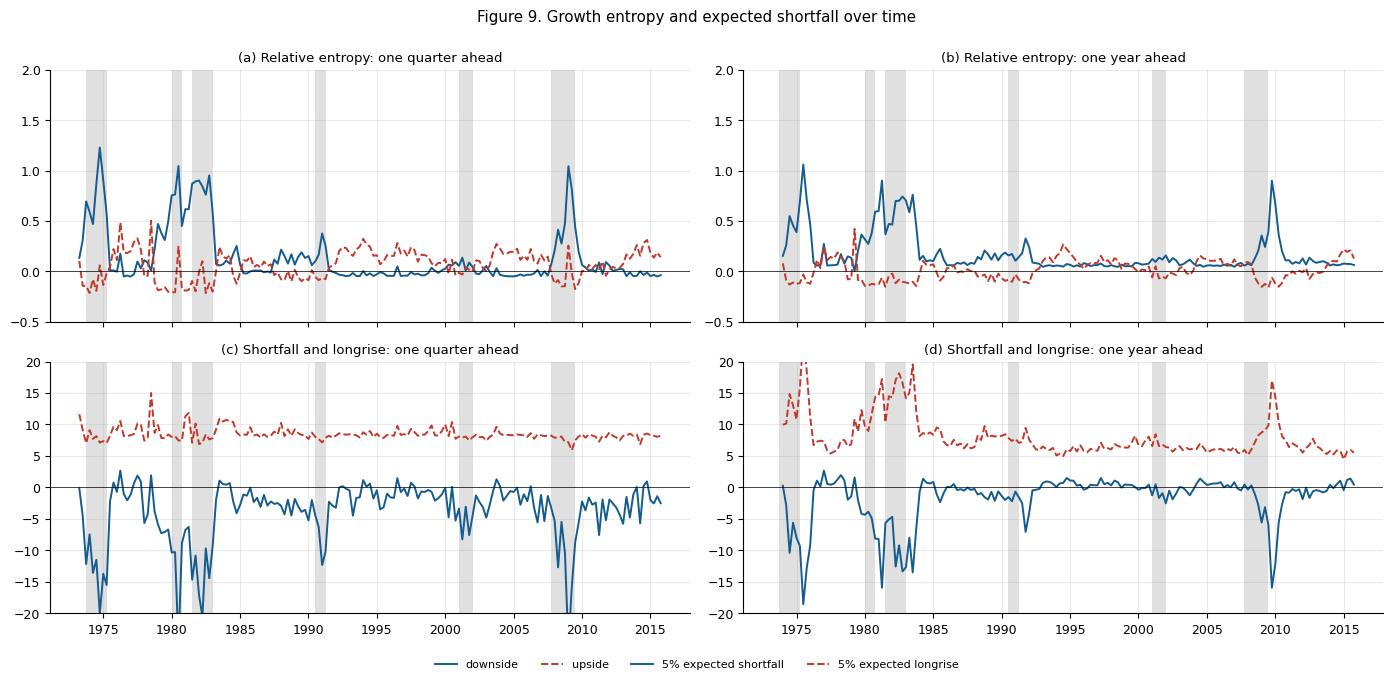

,h=1,h=4
mean downside entropy,0.144,0.178
max downside entropy,1.229,1.06
date of max,1974Q4,1975Q3
mean upside entropy,0.063,0.014
min shortfall,-25.21,-18.56


In [17]:
DY = YY[1] - YY[0]
TAU_ES = np.arange(0.0005, 0.05, 0.001)       # midpoints of 50 equal intervals of [0, 0.05]

def vulnerability(p, p_unc):
    f = np.maximum(dskt(YY, *p), 1e-300)
    g = np.maximum(dskt(YY, *p_unc), 1e-300)
    med = qskt(0.5, *p)[0]
    integrand = (np.log(g) - np.log(f)) * f
    LD = -integrand[YY < med].sum() * DY
    LU = -integrand[YY > med].sum() * DY
    q = qskt(np.r_[TAU_ES, 1 - TAU_ES], *p)
    return LD, LU, q[:len(TAU_ES)].mean(), q[len(TAU_ES):].mean()

VUL = {h: pd.DataFrame([vulnerability(p, STU[h]) for p in ST[h]], index=TDATE[h],
                       columns=["downside entropy", "upside entropy", "shortfall", "longrise"]) for h in H}

fig, axes = plt.subplots(2, 2, figsize=(14, 6.4), sharex=True)
for k, h in enumerate(H):
    v = VUL[h]
    ax = axes[0, k]; shade(ax)
    ax.plot(v.index, v["downside entropy"], color=BLUE, label="downside")
    ax.plot(v.index, v["upside entropy"], color=RED, ls="--", label="upside")
    ax.axhline(0, color="k", lw=0.5); ax.set_ylim(-0.5, 2)
    ax.set_title(f"({'ab'[k]}) Relative entropy: {'one quarter' if h == 1 else 'one year'} ahead")
    ax = axes[1, k]; shade(ax)
    ax.plot(v.index, v["shortfall"], color=BLUE, label="5% expected shortfall")
    ax.plot(v.index, v["longrise"], color=RED, ls="--", label="5% expected longrise")
    ax.axhline(0, color="k", lw=0.5); ax.set_ylim(-20, 20); time_axis(ax)
    ax.set_title(f"({'cd'[k]}) Shortfall and longrise: {'one quarter' if h == 1 else 'one year'} ahead")
fig.suptitle("Figure 9. Growth entropy and expected shortfall over time", y=1.0)
fig.tight_layout(); legend_below(fig, axes[:, 0]); save(fig, "fig09_entropy_shortfall.png"); plt.show()

pd.DataFrame({f"h={h}": {"mean downside entropy": round(VUL[h]["downside entropy"].mean(), 3),
                         "max downside entropy": round(VUL[h]["downside entropy"].max(), 3),
                         "date of max": f"{VUL[h]['downside entropy'].idxmax():%Y}Q{VUL[h]['downside entropy'].idxmax().quarter}",
                         "mean upside entropy": round(VUL[h]["upside entropy"].mean(), 3),
                         "min shortfall": round(VUL[h]["shortfall"].min(), 2)} for h in H})

Downside entropy is close to zero, or slightly negative, most of the time and spikes in the three episodes of financial stress: 1974–75 (maximum 1.23 in 1974Q4 at $h=1$), 1980–82, and 2008–09 (about 1.0). Upside entropy is small throughout (mean 0.06 at $h=1$, 0.01 at $h=4$), so the vulnerability is concentrated on the downside. The 5% expected shortfall falls to between $-15$ and $-25$ in the same episodes (minimum $-25.2$ at $h=1$), while the expected longrise is stable around 8% at $h=1$. At $h=4$ it rises in 1974–83 and 2009, when the predictive distribution is very wide.

### Two additions of ours

**The unconditional density: skewed $t$ or kernel?** A natural alternative for $\hat g$ is a kernel density estimate (KDE) of the historical growth rates, which assumes no functional form. The comparison below fits both and recomputes the downside entropy with the KDE as benchmark.

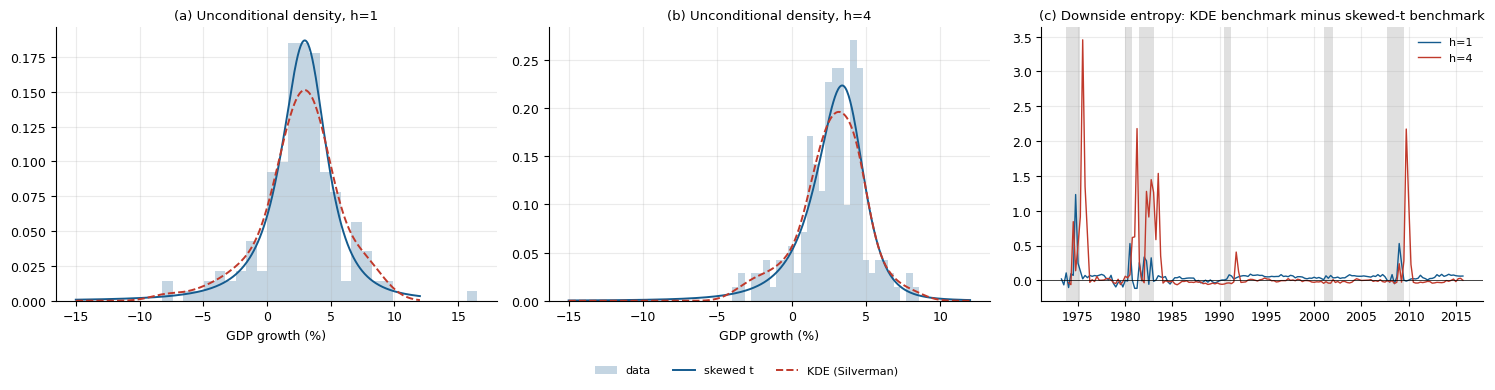

,h=1,h=4
"skewed t: location, scale, shape, df","[3.25, 1.93, -0.26, 2.0]","[4.18, 1.93, -0.93, 3.0]"
"max downside entropy, skewed-t benchmark",1.229,1.06
"max downside entropy, KDE benchmark",2.461,4.513


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
xs = np.linspace(-15, 12, 500)
kde_LD = {}
for k, h in enumerate(H):
    kde = gaussian_kde(Y[h], bw_method="silverman")
    ax = axes[k]
    ax.hist(Y[h], bins=30, density=True, color=BLUE, alpha=0.25, label="data")
    ax.plot(xs, dskt(xs, *STU[h]), color=BLUE, label="skewed t")
    ax.plot(xs, kde(xs), color=RED, ls="--", label="KDE (Silverman)")
    ax.set_title(f"({'ab'[k]}) Unconditional density, h={h}"); ax.set_xlabel("GDP growth (%)")
    g_kde = np.maximum(kde(YY), 1e-300)
    def ld_kde(p):
        f = np.maximum(dskt(YY, *p), 1e-300); med = qskt(0.5, *p)[0]
        return -((np.log(g_kde) - np.log(f)) * f)[YY < med].sum() * DY
    kde_LD[h] = pd.Series([ld_kde(p) for p in ST[h]], index=TDATE[h])
ax = axes[2]; shade(ax)
for h, c in zip(H, [BLUE, RED]):
    ax.plot(VUL[h].index, kde_LD[h] - VUL[h]["downside entropy"], color=c, lw=1, label=f"h={h}")
ax.axhline(0, color="k", lw=0.5); time_axis(ax); ax.legend()
ax.set_title("(c) Downside entropy: KDE benchmark minus skewed-t benchmark")
fig.tight_layout(); legend_below(fig, axes[0]); save(fig, "unconditional_skt_vs_kde.png"); plt.show()

pd.DataFrame({f"h={h}": {"skewed t: location, scale, shape, df": np.round(STU[h], 2).tolist(),
                         "max downside entropy, skewed-t benchmark": round(VUL[h]["downside entropy"].max(), 3),
                         "max downside entropy, KDE benchmark": round(kde_LD[h].max(), 3)} for h in H})

**The KDE benchmark roughly doubles the peaks of downside entropy** (maximum 2.46 against 1.23 at $h=1$, 4.51 against 1.06 at $h=4$) and leaves calm periods unchanged. The reason is the tails, not the shape near the centre. The unconditional skewed $t$ has very fat tails ($\hat\nu = 2$ at $h=1$, 3 at $h=4$), whereas a Gaussian-kernel KDE decays like a normal density beyond the most extreme observations. In recession quarters the conditional density puts mass far in the left tail, where $\hat g_{KDE}$ is much smaller than $\hat g_{SKT}$, so $\log(\hat g/\hat f)$ is much more negative there and the entropy is larger. The skewed-$t$ benchmark is what the paper uses, and it compares two members of the same family, so we keep it for Figure 9.

Note that the paper fits the skewed $t$ to **four** quantiles both for the conditional and for the unconditional distribution.

**A simple measure of vulnerability: $Q_{0.50} - Q_{0.05}$.** The distance between the median and the 5th percentile of the fitted distribution is how far growth can fall below the central scenario in a bad (1-in-20) quarter. Unlike the entropy it needs no benchmark, and unlike the shortfall it is measured relative to the centre.

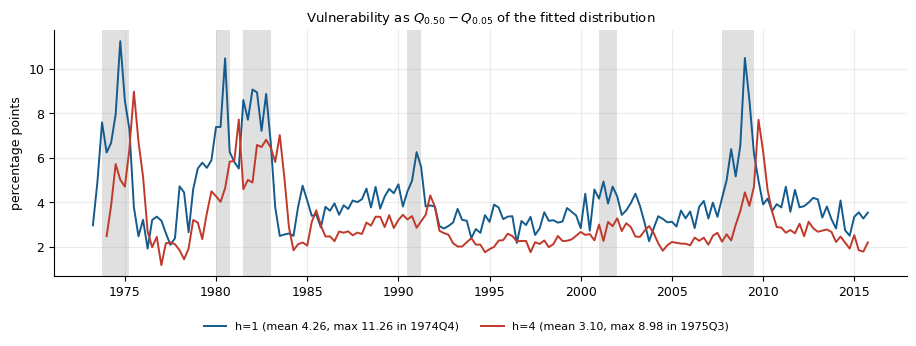

In [19]:
fig, ax = plt.subplots(figsize=(11, 3.2))
shade(ax)
for h, c in zip(H, [BLUE, RED]):
    q = np.array([qskt([0.05, 0.5], *p) for p in ST[h]])
    gap = pd.Series(q[:, 1] - q[:, 0], index=TDATE[h])
    ax.plot(gap.index, gap, color=c, label=f"h={h} (mean {gap.mean():.2f}, max {gap.max():.2f} in "
                                           f"{gap.idxmax():%Y}Q{gap.idxmax().quarter})")
time_axis(ax); ax.set_ylabel("percentage points")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
ax.set_title(r"Vulnerability as $Q_{0.50}-Q_{0.05}$ of the fitted distribution")
save(fig, "vulnerability_q50_q05.png"); plt.show()

The median–5th-percentile gap averages 4.3 points at $h=1$ and 3.1 at $h=4$. It peaks in 1974–75 (11.3 in 1974Q4 at $h=1$), in 1980–82 and in 2008–09 (above 10 at $h=1$), which are the same episodes in which downside entropy spikes. It is a cruder measure, since it uses a single quantile and no benchmark, but it is in percentage points and immediately readable: in 2008–09 a bad quarter was about ten points below the central forecast, against three to four in normal times.

## 10. Parameters and moments over time (Figures A.1–A.4)

The four parameters and the four moments of the fitted distributions, for both horizons. Since the skewed $t$ has no finite variance for $\nu\le 2$ (and no skewness or kurtosis for $\nu\le 3$ or $\nu\le 4$), the moments are computed for the density restricted to the evaluation grid $[-20\%, 20\%]$; this keeps them finite and is what the figures of the paper show.

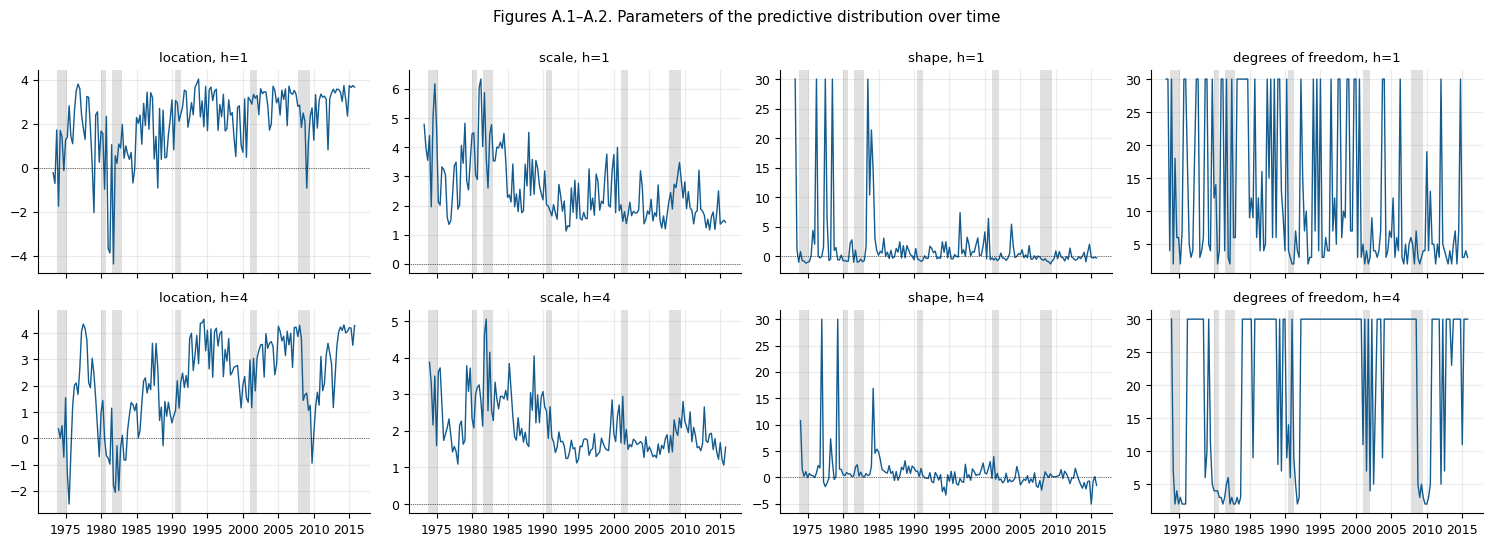

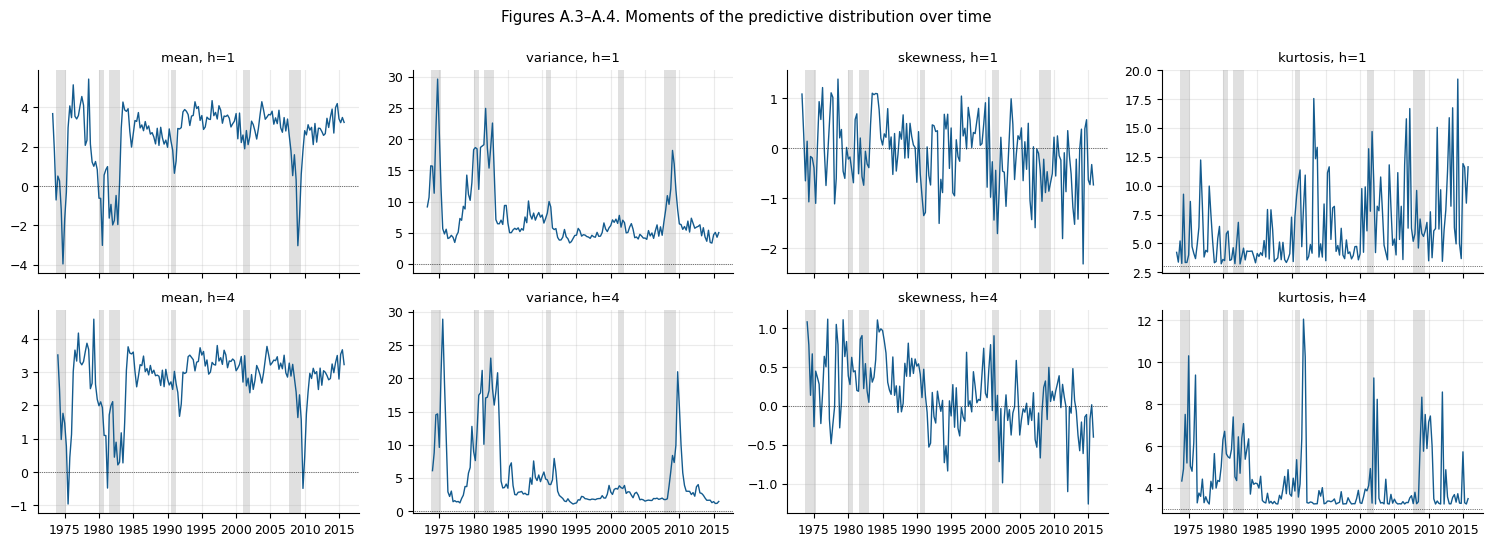

h=1                 h=4             
                     mean   min    max   mean   min    max
location             2.14 -4.38   4.04   2.18 -2.50   4.53
scale                2.55  1.13   6.34   2.08  1.06   5.05
shape                1.55 -1.30  30.00   0.91 -5.05  30.00
degrees of freedom  12.09  2.00  30.00  21.82  2.00  30.00
mean                 2.51 -3.97   5.44   2.76 -0.96   4.59
variance             7.64  3.34  29.61   5.15  1.08  28.90
skewness            -0.12 -2.32   1.39   0.14 -1.26   1.12
kurtosis             6.45  3.22  19.24   4.33  3.23  12.06

In [20]:
MOM = {h: pd.DataFrame([moments(d, YY) for d in DENS[h]], index=TDATE[h],
                       columns=["mean", "variance", "skewness", "kurtosis"]) for h in H}
PAR = {h: pd.DataFrame(ST[h], index=TDATE[h], columns=["location", "scale", "shape", "degrees of freedom"]) for h in H}

for name, D in [("Figures A.1–A.2. Parameters", PAR), ("Figures A.3–A.4. Moments", MOM)]:
    fig, axes = plt.subplots(2, 4, figsize=(15, 5.4), sharex=True)
    for r, h in enumerate(H):
        for c, col in enumerate(D[h].columns):
            ax = axes[r, c]; shade(ax)
            ax.plot(D[h].index, D[h][col], color=BLUE, lw=1)
            if col == "kurtosis": ax.axhline(3, color="k", lw=0.5, ls=":")
            elif col != "degrees of freedom": ax.axhline(0, color="k", lw=0.5, ls=":")
            ax.set_title(f"{col}, h={h}"); time_axis(ax)
    fig.suptitle(f"{name} of the predictive distribution over time", y=1.0)
    fig.tight_layout(); save(fig, ("figA1_A2_parameters.png" if "Param" in name else "figA3_A4_moments.png")); plt.show()

pd.concat({f"h={h}": pd.concat([PAR[h], MOM[h]], axis=1).describe().loc[["mean", "min", "max"]].T for h in H}, axis=1).round(2)

- **Location and scale** (A.1) behave as expected: the location drops and the scale rises in recessions.
- **Shape** (A.2) is mostly between $-2$ and $3$, but in several quarters it jumps to the bound of 30. These are quarters in which the four target quantiles are compatible with a half-$t$, and $\alpha$ is then poorly identified (section 6).
- **Degrees of freedom.** At $h=4$ they sit at the bound of 30 most of the time and drop to 2–5 in the recessions of 1974–75, 1980–82 and 2008–09: the tails get fatter exactly when downside risk rises. At $h=1$ they jump between low values and 30 throughout the sample, a sign that four quantiles identify $\nu$ only weakly.
- **Moments** (A.3–A.4). The mean falls as low as $-4.0$ at $h=1$. The variance rises from about 3–5 in normal times to almost 30 in the worst quarters. Skewness turns negative in recessions (minimum $-2.3$ at $h=1$). Kurtosis is well above 3 throughout (mean 6.5 at $h=1$), so the predictive distributions are fat-tailed even in calm periods.

## 11. Out-of-sample analysis

### Why

Everything so far is in-sample: the regressions use all data up to 2015, so the 2008Q4 distribution was estimated by a model that had already seen the crisis. An out-of-sample exercise reproduces what a forecaster could have done in real time: estimate only on data available at the time, forecast, and only afterwards compare with what happened. As the paper notes, the data are the final revised vintages, not real-time vintages (real-time NFCI data are available only recently), which slightly favours the model.

### The recursive scheme

At each forecast origin $t_0$, from 1993Q1 to the end of the sample:
1. estimate the quantile regressions on the pairs $(x_s, y_{s+h})$ whose target date is no later than $t_0$, i.e. $s\le t_0-h$. For $h = 4$ this means that the four most recent quarters, $t_0-3$ to $t_0$, cannot yet be used as observations, because their four-quarter-ahead outcomes are not known at $t_0$;
2. predict the four quantiles for $t_0+h$ with the current predictors $x_{t_0}$ and fit a skewed $t$;
3. do the same for the GDP-only model and for the unconditional distribution (quantiles of the data available at $t_0$), which is the benchmark for the real-time entropy;
4. evaluate the forecast against the realised $y_{t_0+h}$, which is used only here.

Two questions follow: are the real-time vulnerability measures close to the in-sample ones (**Figure 10**)? And are the real-time densities accurate and well calibrated (**Figure 11**)?

### Predictive score and PIT

The **predictive score** is the predictive density evaluated at the outcome, $PS_t = \hat f_{y_{t+h}\mid x_t}(y^{obs}_{t+h})$: high when the model put a lot of probability where growth actually landed. It measures accuracy and is the natural way to compare models (Gneiting and Raftery, 2007).

The **probability integral transform** is the predictive CDF at the outcome, $PIT_t = \hat F_{y_{t+h}\mid x_t}(y^{obs}_{t+h})$: the percentile of the forecast distribution in which the outcome fell. If the densities are correctly calibrated, the PITs are uniform on $[0,1]$ (Diebold, Gunther and Tay, 1998): an event the model gives 10% probability should happen 10% of the time. Figure 11 plots the empirical CDF of the PITs against the 45-degree line.
- A curve **above** the diagonal at low $\tau$ means too many outcomes in the left tail: the model was **too optimistic**.
- A curve **below** the diagonal at low $\tau$ means too few: the model was **too pessimistic** about the downside.

The critical values follow Rossi and Sekhposyan (2017): for one-step-ahead forecasts the 5% band is $\tau \pm 1.34/\sqrt P$, with $P$ the number of forecasts. For $h = 4$ the forecasts overlap (consecutive targets share three quarters), the PITs are serially correlated, and the paper uses bootstrapped critical values; we show the $h = 1$ band for reference only, and it is too narrow for $h = 4$.

| | predictive score | PIT |
|---|---|---|
| formula | $\hat f(y^{obs})$ | $\hat F(y^{obs})$ |
| measures | accuracy | calibration |
| better | higher | closer to the diagonal |
| used for | comparing models | checking one model |

In [21]:
ONES = lambda n: np.ones((n, 1))

def oos(h):
    rows = []
    for t0 in range(dates.get_loc(pd.Timestamp(OOS_START)), T - h):
        n = t0 - h + 1                                       # pairs with target date <= t0
        x0, y_obs = X[h][t0], Y[h][t0]
        p  = fit_skt(x0 @ qreg(Y[h][:n], X[h][:n], TAU_FIT).T)[0]
        pg = fit_skt(XG[h][t0] @ qreg(Y[h][:n], XG[h][:n], TAU_FIT).T)[0]
        pu = fit_skt(qreg(Y[h][:n], ONES(n), TAU_FIT)[:, 0])[0]
        LD, LU, SF, LR = vulnerability(p, pu)
        q05, q50, q95 = qskt([0.05, 0.5, 0.95], *p)
        rows.append(dict(date=dates[t0 + h], q05=q05, q50=q50, q95=q95, LD=LD,
                         PS=dskt(y_obs, *p), PIT=pskt(y_obs, *p),
                         PS_gdp=dskt(y_obs, *pg), PIT_gdp=pskt(y_obs, *pg)))
    return pd.DataFrame(rows).set_index("date")

t0 = time.time()
OOS = {h: oos(h) for h in H}
print(f"out-of-sample forecasts: h=1 -> {len(OOS[1])}, h=4 -> {len(OOS[4])}; {time.time() - t0:.0f}s")

out-of-sample forecasts: h=1 -> 91, h=4 -> 88; 24s


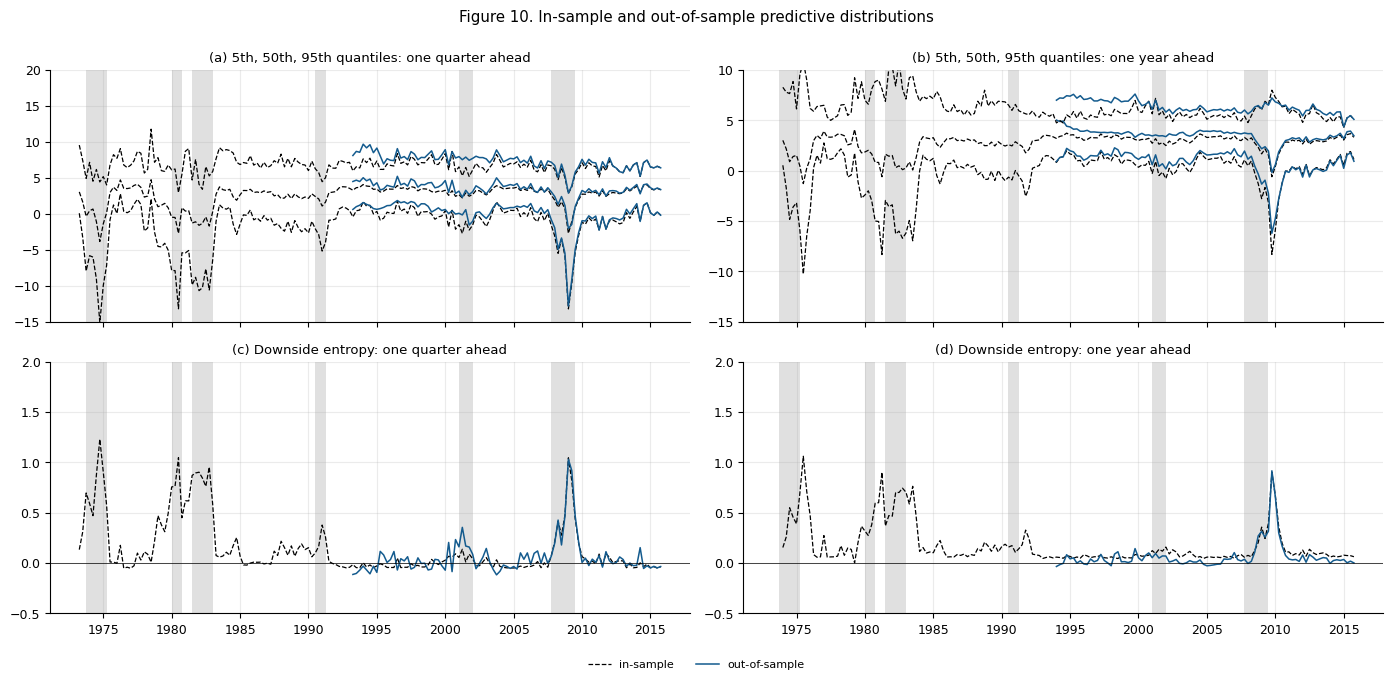

,h=1,h=4
"corr IS/OOS, Q05",0.97,0.96
"corr IS/OOS, downside entropy",0.92,0.96
OOS Q05 in 2008Q4,-5.48,-0.33
IS Q05 in 2008Q4,-5.87,-1.29


In [22]:
QIS = {h: pd.DataFrame(np.array([qskt([0.05, 0.5, 0.95], *p) for p in ST[h]]), index=TDATE[h],
                       columns=["q05", "q50", "q95"]) for h in H}
fig, axes = plt.subplots(2, 2, figsize=(14, 6.4), sharex=True)
for k, h in enumerate(H):
    ax = axes[0, k]; shade(ax)
    for c in ["q05", "q50", "q95"]:
        ax.plot(QIS[h].index, QIS[h][c], color="k", ls="--", lw=0.9, label="in-sample" if c == "q50" else None)
        ax.plot(OOS[h].index, OOS[h][c], color=BLUE, lw=1.1, label="out-of-sample" if c == "q50" else None)
    ax.set_ylim(-15, 20) if h == 1 else ax.set_ylim(-15, 10)
    ax.set_title(f"({'ab'[k]}) 5th, 50th, 95th quantiles: {'one quarter' if h == 1 else 'one year'} ahead")
    ax = axes[1, k]; shade(ax)
    ax.plot(VUL[h].index, VUL[h]["downside entropy"], color="k", ls="--", lw=0.9, label="in-sample")
    ax.plot(OOS[h].index, OOS[h]["LD"], color=BLUE, lw=1.1, label="out-of-sample")
    ax.axhline(0, color="k", lw=0.5); ax.set_ylim(-0.5, 2); time_axis(ax)
    ax.set_title(f"({'cd'[k]}) Downside entropy: {'one quarter' if h == 1 else 'one year'} ahead")
fig.suptitle("Figure 10. In-sample and out-of-sample predictive distributions", y=1.0)
fig.tight_layout(); legend_below(fig, axes[0, 0]); save(fig, "fig10_oos_quantiles_entropy.png"); plt.show()

overlap = {h: OOS[h].index.intersection(QIS[h].index) for h in H}
pd.DataFrame({f"h={h}": {"corr IS/OOS, Q05": np.corrcoef(QIS[h].loc[overlap[h], "q05"], OOS[h].loc[overlap[h], "q05"])[0, 1],
                         "corr IS/OOS, downside entropy": np.corrcoef(VUL[h].loc[overlap[h], "downside entropy"], OOS[h].loc[overlap[h], "LD"])[0, 1],
                         "OOS Q05 in 2008Q4": OOS[h].loc["2008-10-01", "q05"], "IS Q05 in 2008Q4": QIS[h].loc["2008-10-01", "q05"]}
              for h in H}).round(2)

The real-time distributions track the in-sample ones closely. The correlation of the 5th percentile between the two is 0.97 at $h=1$ and 0.96 at $h=4$; for downside entropy it is 0.92 and 0.96. Most importantly, the spike in downside risk in 2008–09 appears in real time, with a model estimated only on data up to the crisis: the out-of-sample 5th percentile for 2008Q4 is $-5.5$ at $h=1$ (in-sample $-5.9$). At $h=4$ the out-of-sample median and upper quantiles are higher than the in-sample ones during the 1990s, when the estimation samples are still short; the two converge after 2008.

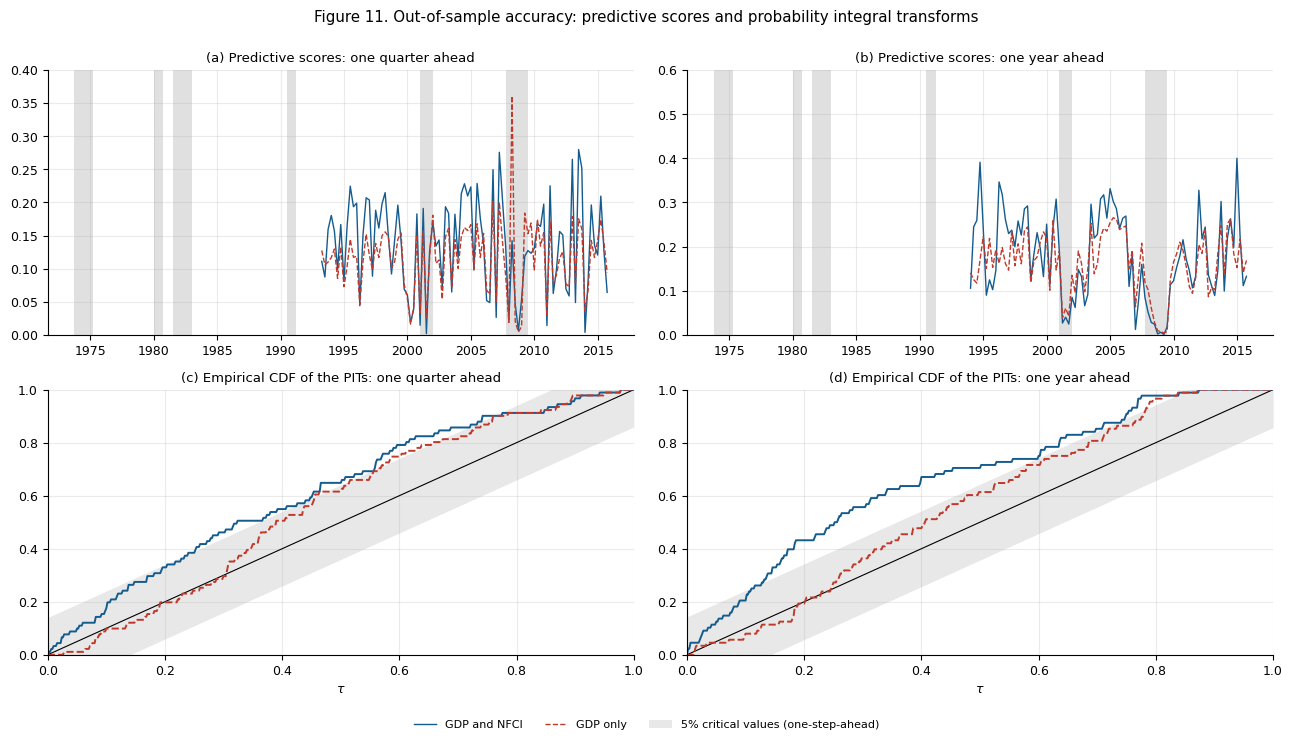

mean score  mean log score  \
h=1 GDP and NFCI                                       0.136          -2.240   
    GDP only                                           0.117          -2.311   
    share of quarters: GDP+NFCI score > GDP only       0.659             NaN   
h=4 GDP and NFCI                                       0.178          -2.022   
    GDP only                                           0.162          -1.992   
    share of quarters: GDP+NFCI score > GDP only       0.545             NaN   

                                                  max |ECDF - tau| x sqrt(P)  \
h=1 GDP and NFCI                                                       1.871   
    GDP only                                                           1.538   
    share of quarters: GDP+NFCI score > GDP only                         NaN   
h=4 GDP and NFCI                                                       2.655   
    GDP only                                                           1.594   
    share of quarters: GDP+NFCI score > GDP only                         NaN   

                                                  mean PIT  
h=1 GDP and NFCI                                     0.379  
    GDP only                                         0.435  
    share of quarters: GDP+NFCI score > GDP only       NaN  
h=4 GDP and NFCI                                     0.330  
    GDP only                                         0.430  
    share of quarters: GDP+NFCI score > GDP only       NaN

In [23]:
KAPPA = 1.34      # Rossi and Sekhposyan (2017), 5% asymptotic critical value for one-step-ahead forecasts
rgrid = np.linspace(0, 1, 501)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
summary = {}
for k, h in enumerate(H):
    o = OOS[h]
    ax = axes[0, k]; shade(ax)
    ax.plot(o.index, o["PS"], color=BLUE, lw=1, label="GDP and NFCI")
    ax.plot(o.index, o["PS_gdp"], color=RED, ls="--", lw=1, label="GDP only")
    ax.set_ylim(0, 0.6 if h == 4 else 0.4); time_axis(ax)
    ax.set_title(f"({'ab'[k]}) Predictive scores: {'one quarter' if h == 1 else 'one year'} ahead")
    ax = axes[1, k]
    P = len(o)
    ax.plot(rgrid, rgrid, color="k", lw=0.8)
    ax.fill_between(rgrid, rgrid - KAPPA / np.sqrt(P), rgrid + KAPPA / np.sqrt(P), color=GREY, alpha=0.2, lw=0,
                    label="5% critical values (one-step-ahead)")
    for col, c, ls, lab in [("PIT", BLUE, "-", "GDP and NFCI"), ("PIT_gdp", RED, "--", "GDP only")]:
        ecdf = (o[col].to_numpy()[:, None] <= rgrid).mean(0)
        ax.plot(rgrid, ecdf, color=c, ls=ls, label=lab)
        summary[(f"h={h}", lab)] = {"mean score": o["PS" if col == "PIT" else "PS_gdp"].mean(),
                                    "mean log score": np.log(o["PS" if col == "PIT" else "PS_gdp"]).mean(),
                                    "max |ECDF - tau| x sqrt(P)": np.abs(ecdf - rgrid).max() * np.sqrt(P),
                                    "mean PIT": o[col].mean()}
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel(r"$\tau$")
    ax.set_title(f"({'cd'[k]}) Empirical CDF of the PITs: {'one quarter' if h == 1 else 'one year'} ahead")
    summary[(f"h={h}", "share of quarters: GDP+NFCI score > GDP only")] = {"mean score": (o["PS"] > o["PS_gdp"]).mean()}
fig.suptitle("Figure 11. Out-of-sample accuracy: predictive scores and probability integral transforms", y=1.0)
fig.tight_layout(); legend_below(fig, axes); save(fig, "fig11_oos_accuracy.png"); plt.show()
pd.DataFrame(summary).T.round(3)

**Accuracy.** Adding the NFCI raises the average predictive score from 0.117 to 0.136 at $h=1$, and the full model scores higher in 66% of quarters. At $h=4$ the gain is smaller (0.162 to 0.178, higher in 55% of quarters). The average *log* score even slightly favours the GDP-only model at $h=4$ ($-1.99$ against $-2.02$), because of a few quarters in 2008–09 in which the realised outcome fell where the full model put almost no density.

**Calibration.** For both models and both horizons the empirical CDF of the PITs lies **above** the diagonal: realised growth fell below the forecast median more often than it should. The average PIT, 0.5 under correct calibration, is 0.38 at $h=1$ and 0.33 at $h=4$ for the full model, and 0.43–0.44 for the GDP-only model. Over 1993–2015 the densities were somewhat too optimistic in the centre. For the full model at $h=1$ the maximum deviation, scaled by $\sqrt P$, is 1.87, above the critical value of 1.34. At $h=1$ the departure is in the middle of the distribution: in the left tail ($\tau\lesssim 0.25$) the curve stays inside the band, so the downside, which is what the model is designed for, is calibrated. These statistics coincide with those implied by the authors' own out-of-sample results, so they are a feature of the data and the method, not of this implementation. At $h=4$ the plotted band is too narrow (see above), and the full model's larger deviation there should be judged against bootstrapped critical values.

## 12. Location-scale models and alternative approaches

### What quantile regression adds

A **location-scale** model lets the conditional distribution move and stretch, but never change shape:

$$y_{t+h} = \mu_t + \sigma_t\,\varepsilon_{t+h},\qquad \varepsilon_{t+h}\sim D(0,1) \text{ with a fixed shape},$$

so that every quantile is $Q_\tau(y_{t+h}\mid x_t) = \mu_t + \sigma_t\, q^D_\tau$, with $q^D_\tau$ constant over time. In terms of the skewed $t$, $\alpha$ and $\nu$ are fixed and only $\mu_t$ and $\sigma_t$ respond to conditions.

- **OLS with Gaussian errors** is the simplest case: $\sigma$ is also constant, $\alpha = 0$, $\nu = \infty$. Tighter financial conditions lower the mean, but the distribution keeps the same symmetric shape, so Growth-at-Risk falls only as much as the mean.
- **Heteroskedastic Gaussian model** (the paper's maximum-likelihood alternative): the variance also depends on the predictors, $\ln\sigma_t^2 = \delta_0 + \delta_1' x_t$. When the NFCI rises the distribution shifts left *and* widens, which already lowers the 5th percentile more than the median, but the distribution stays Gaussian and symmetric.
- **Skewed-$t$ location-scale models** with constant $\alpha$ and $\nu$ add fat tails and a fixed asymmetry.
- **The quantile regression approach** lets all four parameters vary each quarter: asymmetry and tail thickness can change with financial conditions. In a Gaussian location-scale model $\mathrm{GaR}^t_{0.05} = \mu_t - 1.645\,\sigma_t$, with a fixed multiplier; with quantile regression the multiplier itself can change.

| | OLS | heteroskedastic Gaussian | skewed-$t$ location-scale | QR + skewed $t$ |
|---|:---:|:---:|:---:|:---:|
| time-varying $\mu_t$ | ✓ | ✓ | ✓ | ✓ |
| time-varying $\sigma_t$ | ✗ | ✓ | ✓ | ✓ |
| time-varying asymmetry / tails | ✗ | ✗ | ✗ | ✓ |
| fat tails | ✗ | ✗ | ✓ | ✓ |
| estimation | OLS | ML | ML | QR + quantile matching |

### The paper's two alternatives

To check that the results are not an artefact of the two-step procedure, the paper re-estimates the conditional distribution in two very different ways.

**1. Fully parametric: heteroskedastic Gaussian model, by maximum likelihood (equation 7).**

$$y_{t+1} = \gamma_0 + \gamma_1' x_t + \sigma_t\varepsilon_{t+1},\qquad \ln\sigma_t^2 = \delta_0 + \delta_1' x_t,\qquad \varepsilon_{t+1}\sim\mathcal N(0,1),$$

with log-likelihood $\ell = -\tfrac12\sum_t\big[\ln(2\pi\sigma_t^2) + (y_{t+1}-\gamma_0-\gamma_1'x_t)^2/\sigma_t^2\big]$.

**2. Fully non-parametric: kernel estimate of the conditional CDF (Li, Lin and Racine, 2013; equation 8).**

$$\hat F_{y_{t+1}\mid x_t}(y\mid x) = \frac{\sum_t \Phi\!\left(\frac{y-y_{t+1}}{\omega_0}\right)K_\omega(x_t,x)}{\sum_t K_\omega(x_t,x)},\qquad K_\omega(x_t,x) = \prod_i\frac{1}{\omega_i}\phi\!\left(\frac{x_i-x_{it}}{\omega_i}\right).$$

It is a weighted average of smoothed indicator functions centred on past outcomes, with weights that are larger the more similar past conditions $x_t$ were to current conditions $x$. The bandwidths $\omega$ are chosen by leave-one-out cross-validation of the likelihood. Small bandwidths make the estimate local and noisy; large ones smooth it towards the unconditional distribution. The method needs no distributional assumption, but it needs many observations to be accurate in the tails and its parameters have no economic interpretation.

Other approaches mentioned in the paper include Markov-switching models (Hamilton, 1989), semi-parametric copulas (Chen, Fan and Tsyrennikov, 2006), Bayesian VARs with stochastic volatility (Primiceri, 2005; Clark, 2011) and sieve methods.

h=1: MLE gamma=[ 2.04  0.26 -0.85], delta=[1.94 0.01 0.54]; CV bandwidths (y, GDP, NFCI) = [1.69 4.26 0.89]


h=4: MLE gamma=[ 2.17  0.19 -0.82], delta=[1.15 0.   0.79]; CV bandwidths (y, GDP, NFCI) = [1.   4.89 0.4 ]


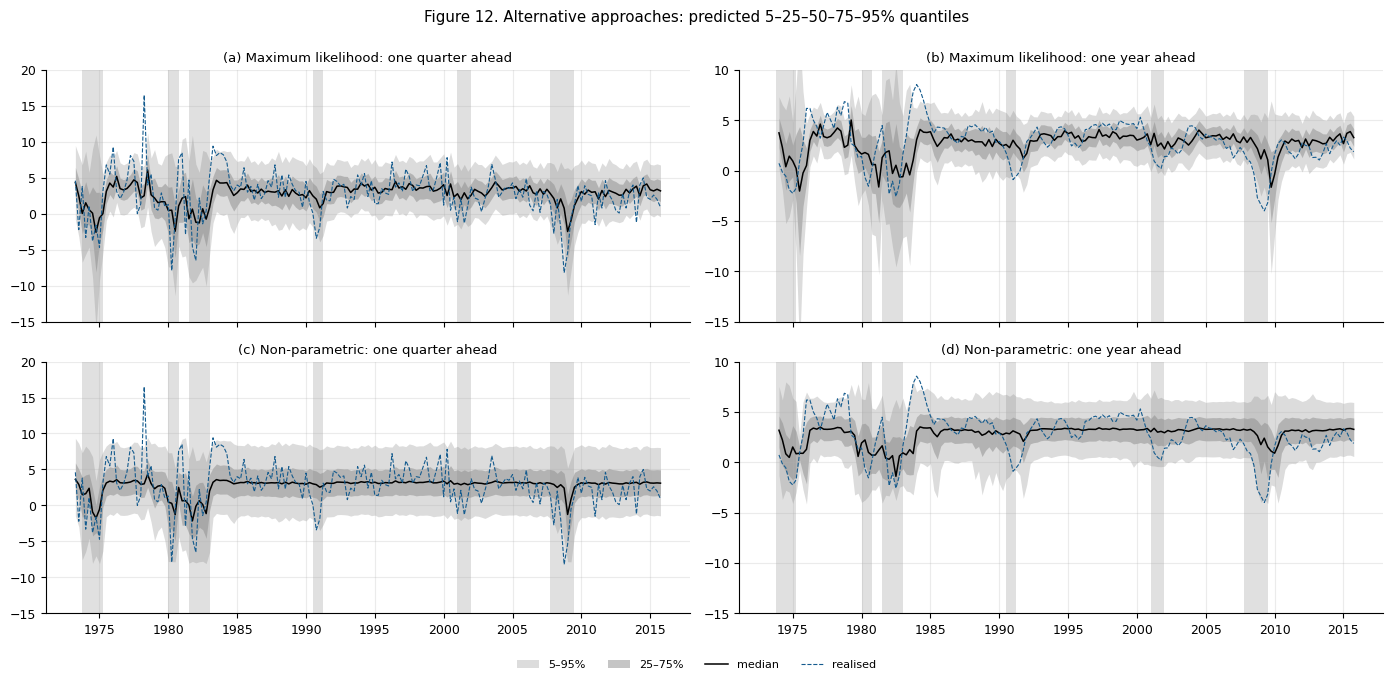

In [24]:
def mle_hetero(Z, y):
    """Gaussian model with log-linear variance: returns gamma, delta."""
    k = Z.shape[1]
    nll = lambda th: 0.5 * np.sum(np.clip(Z @ th[k:], -10, 10) + np.log(2 * np.pi)
                                  + (y - Z @ th[:k]) ** 2 / np.exp(np.clip(Z @ th[k:], -10, 10)))
    g0 = np.linalg.lstsq(Z, y, rcond=None)[0]
    d0 = np.r_[np.log(np.var(y - Z @ g0)), np.zeros(k - 1)]
    th = optimize.minimize(nll, np.r_[g0, d0], method="BFGS", options={"gtol": 1e-8, "maxiter": 5000}).x
    return th[:k], th[k:]

def cv_bandwidths(Xk, y):
    """Leave-one-out likelihood cross-validation for the kernel conditional density."""
    n, p = Xk.shape
    def loss(logw):
        w = np.exp(logw); w0, wx = w[0], w[1:]
        logK = sum(norm.logpdf((Xk[:, [j]] - Xk[:, j][None, :]) / wx[j]) for j in range(p))
        np.fill_diagonal(logK, -np.inf)
        K = np.exp(logK - logK.max(1, keepdims=True)); K /= K.sum(1, keepdims=True)
        f = (K * norm.pdf((y[:, None] - y[None, :]) / w0)).sum(1) / w0
        return -np.log(np.maximum(f, 1e-12)).sum()
    silverman = 1.06 * np.std(np.column_stack([y, Xk]), axis=0) * n ** -0.2
    return np.exp(optimize.minimize(loss, np.log(silverman), method="L-BFGS-B").x)

def kernel_cdf(ygrid, x, Xk, y, w):
    logK = sum(norm.logpdf((Xk[:, j] - x[j]) / w[1 + j]) for j in range(Xk.shape[1]))
    K = np.exp(logK - logK.max()); K /= K.sum()
    return norm.cdf((ygrid[:, None] - y[None, :]) / w[0]) @ K

def kernel_quantiles(taus, x, Xk, y, w):
    yg = np.linspace(y.min() - 4 * w[0], y.max() + 4 * w[0], 1500)
    return np.interp(taus, kernel_cdf(yg, x, Xk, y, w), yg)

TAU5 = np.array([0.05, 0.25, 0.5, 0.75, 0.95])
ALT, BW = {}, {}
for h in H:
    g, d = mle_hetero(X[h], Y[h])
    ALT[(h, "MLE")] = (X[h] @ g)[:, None] + np.sqrt(np.exp(X[h] @ d))[:, None] * norm.ppf(TAU5)
    BW[h] = cv_bandwidths(X[h][:, 1:], Y[h])
    ALT[(h, "NP")] = np.array([kernel_quantiles(TAU5, X[h][i, 1:], X[h][:, 1:], Y[h], BW[h]) for i in range(len(Y[h]))])
    print(f"h={h}: MLE gamma={np.round(g, 2)}, delta={np.round(d, 2)}; CV bandwidths (y, GDP, NFCI) = {np.round(BW[h], 2)}")

fig, axes = plt.subplots(2, 2, figsize=(14, 6.4), sharex=True)
for c, h in enumerate(H):
    for r, m in enumerate(["MLE", "NP"]):
        ax = axes[r, c]; shade(ax); q = ALT[(h, m)]
        ax.fill_between(TDATE[h], q[:, 0], q[:, 4], color=GREY, alpha=0.3, lw=0, label="5–95%")
        ax.fill_between(TDATE[h], q[:, 1], q[:, 3], color=GREY, alpha=0.5, lw=0, label="25–75%")
        ax.plot(TDATE[h], q[:, 2], color="k", lw=1.1, label="median")
        ax.plot(TDATE[h], Y[h], color=BLUE, lw=0.8, ls="--", label="realised")
        ax.set_ylim(-15, 20) if h == 1 else ax.set_ylim(-15, 10); time_axis(ax)
        ax.set_title(f"({'abcd'[2 * r + c]}) {'Maximum likelihood' if m == 'MLE' else 'Non-parametric'}: "
                     f"{'one quarter' if h == 1 else 'one year'} ahead")
fig.suptitle("Figure 12. Alternative approaches: predicted 5–25–50–75–95% quantiles", y=1.0)
fig.tight_layout(); legend_below(fig, axes[0, 0]); save(fig, "fig12_alternative_approaches.png"); plt.show()

Both alternatives reproduce the main qualitative feature: the lower quantiles fall sharply in recessions while the upper ones move much less.
- **Maximum likelihood.** The variance equation does the work. The NFCI raises the log variance ($\hat\delta^{NFCI} = 0.54$ at $h=1$, $0.79$ at $h=4$) while current GDP hardly affects it, so a tightening lowers the mean *and* widens the distribution, and the 5th percentile drops more than the median even though the distribution is symmetric.
- **Kernel estimator.** It is much smoother. The cross-validated bandwidth for current GDP is very large (4.3 and 4.9 percentage points, more than the standard deviation of GDP growth), so current growth barely matters, and the predicted distribution moves only when the NFCI is far from its usual values: 1974–75, 1980–82, 2008–09. Outside those episodes its quantiles are almost constant.

### Out-of-sample performance of the alternatives (Figure A.8)

The same recursive exercise, one quarter ahead, for the two alternatives. The kernel bandwidths are re-chosen by cross-validation at every forecast origin, using only the data available at that origin. The benchmark in the score panels is the quantile-regression model with GDP only, as in the paper.

alternative out-of-sample exercise: 17s


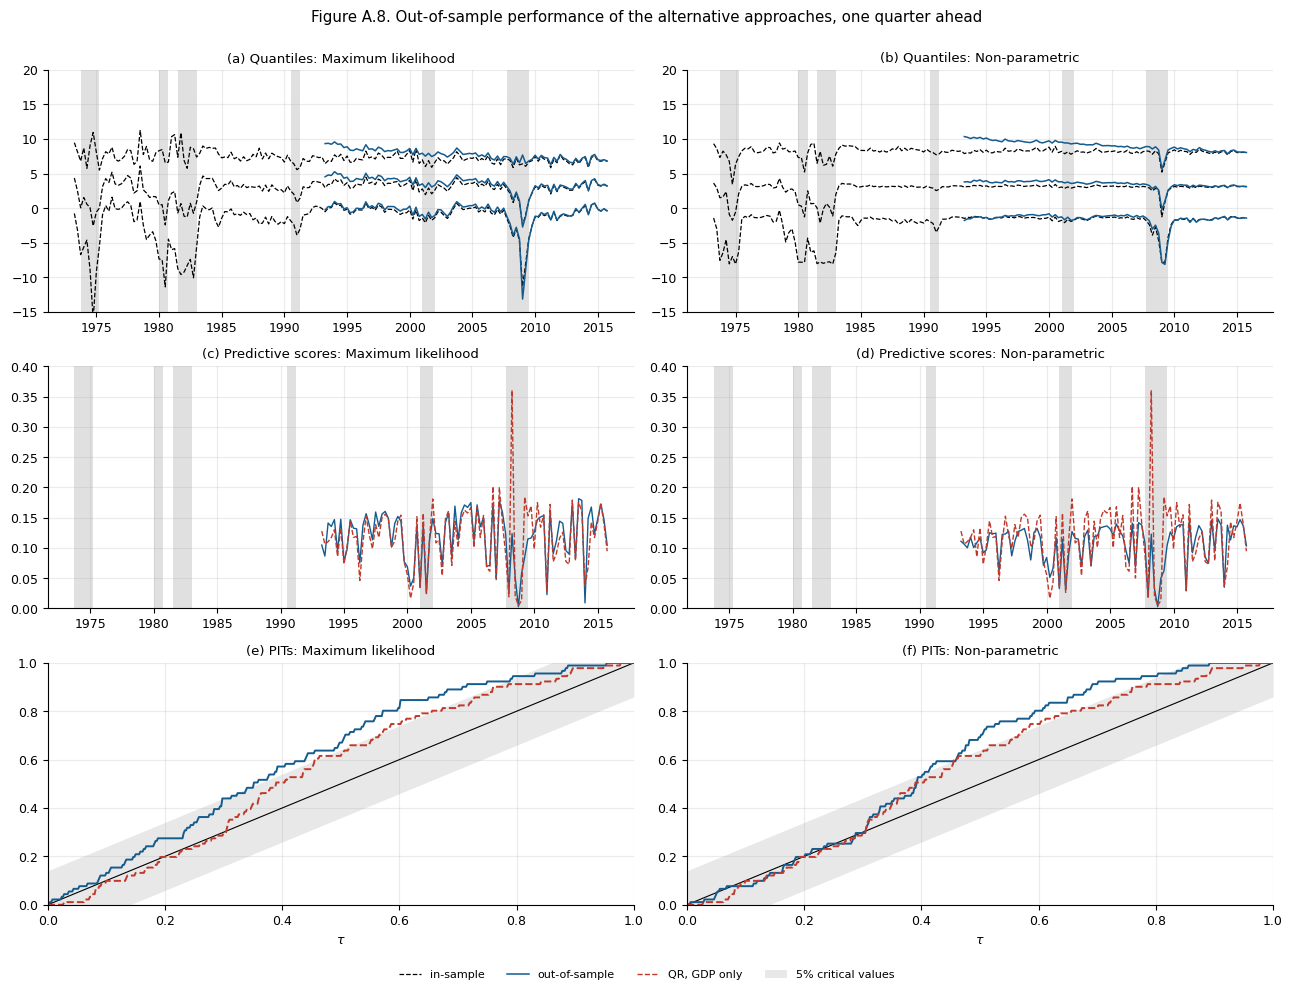

,h=1,h=4
mean predictive score,,
"QR, GDP + NFCI",0.136,0.178
"QR, GDP only",0.117,0.162
maximum likelihood,0.119,0.182
non-parametric,0.106,0.162


,h=1,h=4
max |ECDF(PIT) - tau| x sqrt(P),,
"QR, GDP + NFCI",1.87,2.65
"QR, GDP only",1.54,1.59
maximum likelihood,2.33,2.43
non-parametric,2.14,2.31


In [25]:
def oos_alt(h):
    rows = []
    for t0 in range(dates.get_loc(pd.Timestamp(OOS_START)), T - h):
        n = t0 - h + 1
        x0, y_obs = X[h][t0], Y[h][t0]
        g, d = mle_hetero(X[h][:n], Y[h][:n])
        mu, sd = x0 @ g, np.sqrt(np.exp(np.clip(x0 @ d, -10, 10)))
        w = cv_bandwidths(X[h][:n, 1:], Y[h][:n])
        qnp = kernel_quantiles([0.05, 0.5, 0.95], x0[1:], X[h][:n, 1:], Y[h][:n], w)
        logK = sum(norm.logpdf((X[h][:n, 1 + j] - x0[1 + j]) / w[1 + j]) for j in range(2))
        K = np.exp(logK - logK.max()); K /= K.sum()
        rows.append(dict(date=dates[t0 + h],
                         ml_q05=mu + sd * norm.ppf(.05), ml_q50=mu, ml_q95=mu + sd * norm.ppf(.95),
                         ml_PS=norm.pdf(y_obs, mu, sd), ml_PIT=norm.cdf(y_obs, mu, sd),
                         np_q05=qnp[0], np_q50=qnp[1], np_q95=qnp[2],
                         np_PS=np.sum(K * norm.pdf(y_obs, Y[h][:n], w[0])),
                         np_PIT=np.sum(K * norm.cdf((y_obs - Y[h][:n]) / w[0]))))
    return pd.DataFrame(rows).set_index("date")

t0 = time.time()
OOS_ALT = {h: oos_alt(h) for h in H}
print(f"alternative out-of-sample exercise: {time.time() - t0:.0f}s")

o, oa = OOS[1], OOS_ALT[1]
fig, axes = plt.subplots(3, 2, figsize=(13, 9.5))
for c, (m, lab) in enumerate([("ml", "Maximum likelihood"), ("np", "Non-parametric")]):
    ax = axes[0, c]; shade(ax)
    is_q = ALT[(1, "MLE" if m == "ml" else "NP")]
    for j, col in [(0, "q05"), (2, "q50"), (4, "q95")]:
        ax.plot(TDATE[1], is_q[:, j], color="k", ls="--", lw=0.9, label="in-sample" if j == 2 else None)
        ax.plot(oa.index, oa[f"{m}_{col}"], color=BLUE, lw=1.1, label="out-of-sample" if j == 2 else None)
    ax.set_ylim(-15, 20); time_axis(ax); ax.set_title(f"({'ab'[c]}) Quantiles: {lab}")
    ax = axes[1, c]; shade(ax)
    ax.plot(oa.index, oa[f"{m}_PS"], color=BLUE, lw=1, label="out-of-sample")
    ax.plot(o.index, o["PS_gdp"], color=RED, ls="--", lw=1, label="QR, GDP only")
    ax.set_ylim(0, 0.4); time_axis(ax); ax.set_title(f"({'cd'[c]}) Predictive scores: {lab}")
    ax = axes[2, c]
    P = len(oa)
    ax.plot(rgrid, rgrid, color="k", lw=0.8)
    ax.fill_between(rgrid, rgrid - KAPPA / np.sqrt(P), rgrid + KAPPA / np.sqrt(P), color=GREY, alpha=0.2, lw=0, label="5% critical values")
    ax.plot(rgrid, (oa[f"{m}_PIT"].to_numpy()[:, None] <= rgrid).mean(0), color=BLUE, label="out-of-sample")
    ax.plot(rgrid, (o["PIT_gdp"].to_numpy()[:, None] <= rgrid).mean(0), color=RED, ls="--", label="QR, GDP only")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel(r"$\tau$"); ax.set_title(f"({'ef'[c]}) PITs: {lab}")
fig.suptitle("Figure A.8. Out-of-sample performance of the alternative approaches, one quarter ahead", y=1.0)
fig.tight_layout(); legend_below(fig, axes[:, 0]); save(fig, "figA8_alternative_oos.png"); plt.show()

display(pd.DataFrame({f"h={h}": {"QR, GDP + NFCI": OOS[h]["PS"].mean(), "QR, GDP only": OOS[h]["PS_gdp"].mean(),
                         "maximum likelihood": OOS_ALT[h]["ml_PS"].mean(), "non-parametric": OOS_ALT[h]["np_PS"].mean()}
              for h in H}).rename_axis("mean predictive score").round(3))
ks = lambda pit: np.abs((np.asarray(pit)[:, None] <= rgrid).mean(0) - rgrid).max() * np.sqrt(len(pit))
display(pd.DataFrame({f"h={h}": {"QR, GDP + NFCI": ks(OOS[h]["PIT"]), "QR, GDP only": ks(OOS[h]["PIT_gdp"]),
                                 "maximum likelihood": ks(OOS_ALT[h]["ml_PIT"]), "non-parametric": ks(OOS_ALT[h]["np_PIT"])}
                      for h in H}).rename_axis("max |ECDF(PIT) - tau| x sqrt(P)").round(2))

Out of sample, the maximum-likelihood model performs about as well as the quantile regression with GDP only at $h=1$ (average score 0.119 against 0.117) and slightly better than all models at $h=4$ (0.182). The kernel estimator is the weakest at $h=1$ (0.106): with bandwidths re-estimated in real time it is close to the unconditional distribution most of the time. None beats the full quantile-regression model at $h=1$ (0.136). The PIT curves show the same optimism in the centre of the distribution as the quantile regressions, and more of it: the maximum scaled deviation from the diagonal at $h=1$ is 2.33 for maximum likelihood and 2.14 for the kernel estimator, against 1.87 for the full quantile-regression model and 1.54 for the GDP-only one.

## 13. Implications for theories of macroeconomic dynamics

### The main finding

Current economic conditions forecast the median of future GDP growth; financial conditions forecast its downside; the upside is comparatively stable. Financial conditions matter for the **shape** of the distribution, not only for its mean.

### Credit demand

The credit-channel literature (Bernanke and Gertler, 1995; Brunnermeier, Eisenbach and Sannikov, 2013) stresses frictions on the borrowers' side: asymmetric information and moral hazard make tighter financial conditions erode borrowers' net worth, which amplifies downturns. But the most common DSGE implementations of these frictions are solved to first order, and in a first-order solution financial vulnerability cannot affect the higher moments of GDP growth. Since financial conditions are correlated precisely with those higher moments (asymmetry, tails), non-linear solutions are needed to match the data.

### Credit supply

After the Great Recession, models with frictions in the supply of credit (Brunnermeier and Sannikov, 2014; He and Krishnamurthy, 2012; Adrian and Boyarchenko, 2012) put the balance sheets of intermediaries at the centre. These models are solved globally and feature a **non-linear amplification** channel through intermediaries' capital constraints. They produce a *volatility paradox*: periods of low volatility come with high average growth and build up the risk of later downturns, while periods of low growth come with high volatility. Mean and volatility of growth should therefore be **negatively correlated**, which is what Figure 13 tests.

### Other mechanisms

- **Learning:** models of aggregate Bayesian learning (Orlik and Veldkamp, 2014; Johannes, Lochstoer and Mou, 2016) can generate a negative link between conditional mean and volatility if agents use financial conditions as a signal about future risks.
- **Disaster risk** (Barro, 2009; Gabaix, 2012; Wachter, 2013) generates high equity premia from rare catastrophes, but GDP vulnerability changes from quarter to quarter while exposure to disasters changes slowly. Term structures of risk premia across asset classes (van Binsbergen, Hueskes, Koijen and Vrugt, 2013) point instead to non-linear shocks at intermediate frequencies, more in line with the fast movements of downside entropy.

### Figures 13 and 14

Figure 13 plots, quarter by quarter, the **mean** of the fitted distribution against its **standard deviation** and against the **downside entropy**. Note that the mean is not the location parameter $\mu_t$: with $\alpha_t<0$ the mean lies below $\mu_t$. Figure 14 shows the cross-correlations at leads and lags: the value at lag $k$ is $\mathrm{corr}(\text{mean}_t,\ v_{t-k})$, where $v$ is volatility or entropy, so $k>0$ means that the vulnerability measure **precedes** the mean. The dashed lines are $\pm 1.96/\sqrt n$; because both series are very persistent, these bands understate the uncertainty.

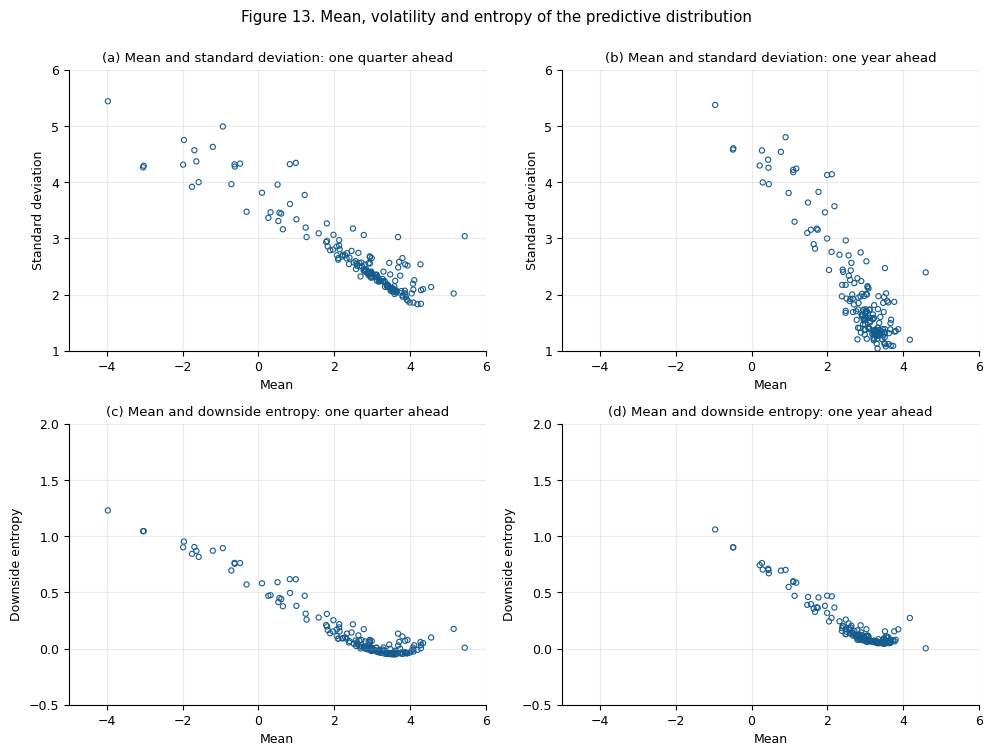

Contemporaneous correlations with the mean: {('h=1', 'Standard deviation'): -0.92, ('h=1', 'Downside entropy'): -0.94, ('h=4', 'Standard deviation'): -0.9, ('h=4', 'Downside entropy'): -0.94}


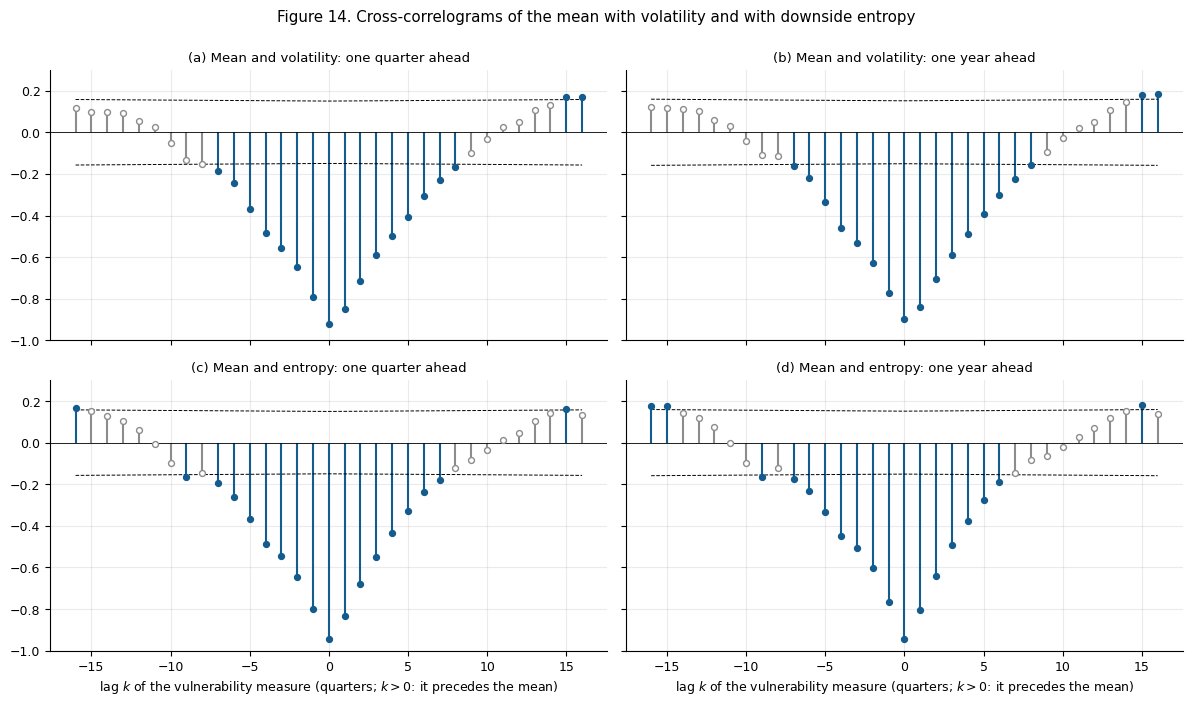

corr at k=0 corr at k=+1 corr at k=-1  \
h=1 volatility       -0.92        -0.85        -0.79   
    entropy          -0.94        -0.83         -0.8   
h=4 volatility        -0.9        -0.84        -0.77   
    entropy          -0.94         -0.8        -0.76   

               significant negative block  
h=1 volatility                    -7 to 8  
    entropy                       -7 to 7  
h=4 volatility                    -7 to 8  
    entropy                       -7 to 6

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
corr0 = {}
for c, h in enumerate(H):
    mean, sd, ld = MOM[h]["mean"], np.sqrt(MOM[h]["variance"]), VUL[h]["downside entropy"]
    for r, (v, lab, ylim) in enumerate([(sd, "Standard deviation", (1, 6)), (ld, "Downside entropy", (-0.5, 2))]):
        ax = axes[r, c]
        ax.scatter(mean, v, s=14, facecolors="none", edgecolors=BLUE, lw=0.8)
        ax.set_xlim(-5, 6); ax.set_ylim(ylim); ax.set_xlabel("Mean"); ax.set_ylabel(lab)
        ax.set_title(f"({'abcd'[2 * r + c]}) Mean and {lab.lower()}: {'one quarter' if h == 1 else 'one year'} ahead")
        corr0[(f"h={h}", lab)] = np.corrcoef(mean, v)[0, 1]
fig.suptitle("Figure 13. Mean, volatility and entropy of the predictive distribution", y=1.0)
fig.tight_layout(); save(fig, "fig13_mean_vol_entropy.png"); plt.show()
print("Contemporaneous correlations with the mean:", {k: round(float(v), 2) for k, v in corr0.items()})

LAGS = np.arange(-16, 17)
def crosscorr(a, b, lags):
    """corr(a_t, b_{t-k}) for each k, with the number of overlapping observations"""
    a, b = np.asarray(a), np.asarray(b); out, ns = [], []
    for k in lags:
        x, y = (a[k:], b[:len(b) - k]) if k >= 0 else (a[:k], b[-k:])
        out.append(np.corrcoef(x, y)[0, 1]); ns.append(len(x))
    return np.array(out), np.array(ns)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
peak = {}
for c, h in enumerate(H):
    mean = MOM[h]["mean"].to_numpy()
    for r, (v, lab) in enumerate([(np.sqrt(MOM[h]["variance"]).to_numpy(), "volatility"),
                                  (VUL[h]["downside entropy"].to_numpy(), "entropy")]):
        cc, ns = crosscorr(mean, v, LAGS); band = 1.96 / np.sqrt(ns)
        ax = axes[r, c]; sig = np.abs(cc) > band
        ax.vlines(LAGS, 0, cc, color=np.where(sig, BLUE, GREY), lw=1.5)
        ax.scatter(LAGS[sig], cc[sig], color=BLUE, s=18, zorder=3)
        ax.scatter(LAGS[~sig], cc[~sig], facecolors="white", edgecolors=GREY, s=18, zorder=3)
        ax.plot(LAGS, band, color="k", ls="--", lw=0.7); ax.plot(LAGS, -band, color="k", ls="--", lw=0.7)
        ax.axhline(0, color="k", lw=0.6); ax.set_ylim(-1, 0.3)
        ax.set_title(f"({'abcd'[2 * r + c]}) Mean and {lab}: {'one quarter' if h == 1 else 'one year'} ahead")
        if r == 1: ax.set_xlabel(r"lag $k$ of the vulnerability measure (quarters; $k>0$: it precedes the mean)")
        neg = sig & (cc < 0)                                   # contiguous block of significant negative values around k=0
        i0 = int(np.where(LAGS == 0)[0][0]); lo = hi = i0
        while lo > 0 and neg[lo - 1]: lo -= 1
        while hi < len(LAGS) - 1 and neg[hi + 1]: hi += 1
        peak[(f"h={h}", lab)] = {"corr at k=0": round(cc[i0], 2), "corr at k=+1": round(cc[i0 + 1], 2), "corr at k=-1": round(cc[i0 - 1], 2),
                                 "significant negative block": f"{LAGS[lo]} to {LAGS[hi]}"}
fig.suptitle("Figure 14. Cross-correlograms of the mean with volatility and with downside entropy", y=1.0)
fig.tight_layout(); save(fig, "fig14_crosscorrelograms.png"); plt.show()
pd.DataFrame(peak).T.round(2)

The negative relation between the mean and the two vulnerability measures is very strong. The contemporaneous correlation of the mean is about $-0.9$ with the standard deviation and $-0.94$ with downside entropy, at both horizons. Quarters with low expected growth are both more uncertain and more exposed to downside risk, which is consistent with the volatility paradox of the credit-supply models and inconsistent with a location-scale model with constant variance (which would put all points on a horizontal line).

The cross-correlograms are almost symmetric and remain significantly negative from $k=-7$ to $k=+6$–$8$ (see the table), i.e. for almost two years before and after. The correlation is slightly stronger when the vulnerability measure leads ($k=+1$: $-0.85$ for volatility at $h=1$) than when it lags ($k=-1$: $-0.79$). High volatility and entropy both precede and follow low expected growth. The isolated positive correlations at $|k|\ge 15$ are not meaningful: with series this persistent the $\pm1.96/\sqrt n$ bands are too narrow.

The mean and standard deviation are those of the fitted distribution, as in the paper, not its location and scale parameters.

## 14. Summary and differences from the paper

**What replicates.** Using only the published data file:
- the predicted quantiles coincide with the authors' to $10^{-5}$ (the quantile regressions are solved exactly as linear programmes);
- the skewed-$t$ parameters coincide with those in the authors' replication files for almost every quarter (same $\nu$ in 96% of quarters at $h=1$ and 99% at $h=4$, location and scale within 0.1);
- the summary statistics of the out-of-sample exercise (average scores, PIT deviations) match those implied by the authors' results;
- all figures reproduce the paper's qualitative findings. The NFCI shifts the left tail of future growth much more than the right tail; downside entropy and expected shortfall spike in 1974–75, 1980–82 and 2008–09; the vulnerability measures are almost unchanged in real time; and mean and volatility of growth are strongly negatively correlated.

**Choices and caveats.**
- The bootstrap bands of Figure 4 come from our own 1,000 VAR draws, so they differ from the paper's by simulation noise.
- For $h=4$ the PIT critical values are not bootstrapped; the band shown is the one-step-ahead value.
- Moments are computed on the truncated grid $[-20, 20]$.
- Out of sample, the PITs indicate that the densities were too optimistic in the centre of the distribution over 1993–2015; at $h=1$ the left tail is well calibrated.